# ES-BMA for nanosheet exfoliation: reproduction of all analyses and figures

This notebook reproduces every quantitative result and figure of the paper (exhaustive search over all
linear models of 16 descriptors with Bayesian model averaging, **ES-BMA**, compared with **Bolasso**).

**Unified ES-BMA setting.** All ES-BMA analyses of the yield data (Fig 3–7) use one setting, that of Fig 4:
`exhbma` 0.1.12, σ<sub>ε</sub> and σ<sub>w</sub> on the grid `inverse(logspace(-2.5, 2.5, 30))` (30 points,
10<sup>-2.5</sup>–10<sup>2.5</sup>, prior ∝ 1/σ), all 2<sup>16</sup> models, X standardised and y centred by the exhbma scalers.
A single fit of the 80 samples therefore serves Fig 3, 4, 5 and 7. The sample-size studies (Fig 8, Fig 9; 1,290 ES-BMA
fits) were recomputed with the same grid by `scripts/recompute_grid30/`, using the fast evaluator
`src/esbma_repro/fast_evidence.py` (identical evidences to exhbma, ≈ 400× faster). Values that the paper quoted for the earlier, mixed settings are listed in the
README (“Changes from the earlier settings”).

| Section | Paper item |
|---|---|
| 1 | Fig 3 – weight diagrams (BFE ranks 1–100 and 59,951–60,050) and prediction plots (BFE ranks 1, 100, 60,000) |
| 2 | Fig 4 – Bolasso selection probabilities vs ES-BMA feature posteriors, real yield data (N = 80) + text statistics |
| 3 | Fig 5 – joint posterior of (σ<sub>ε</sub>, σ<sub>w</sub>) at N = 80 |
| 4 | Fig 6 – synthetic target y = 1.0·x8 + ε (30 noise realisations) |
| 5 | Fig 7 – density of states of the 5-fold CVE of all 65,535 models; Bolasso / ES-BMA model capture |
| 6 | Fig 8 – feature posterior vs sample size (yield, subsampling) |
| 7 | Fig 9 – mean posterior of the max/min feature vs number of samples (yield, size, size distribution) |
| 8 | Summary of all checked numbers |

**How to run.** Run all cells from the repository root (all paths are relative).
Every section has a `RECOMPUTE_*` flag. With the default `False` the section loads the cached intermediate
results in `data/intermediate/` (whole notebook: under one minute). With `True` it recomputes them from
the raw data in `data/raw/` with the code in `src/` and compares the result with the cached file.
All flags can be switched on at once with the environment variable `ESBMA_RECOMPUTE=1`;
`ESBMA_QUICK=1` keeps the heavy steps (Fig 5 convergence, Fig 6, Fig 8, Fig 9) at a reduced size (see README for run
times); `ESBMA_EXHBMA=1` uses the original (≈ 400× slower) exhbma loop instead of the fast evaluator.
Recomputed files are written to `results/` and never overwrite `data/intermediate/`.

In [1]:
import os, sys, json, gzip, time, warnings
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from IPython.display import Image, display

sys.path.insert(0, os.path.abspath("src"))          # vendored exhbma 0.1.12 + esbma_repro
import exhbma
from esbma_repro import data as D, esbma, bolasso, dos, synth, subsample, fig3
from esbma_repro import fast_evidence as FE

RECOMPUTE_ALL = os.environ.get("ESBMA_RECOMPUTE", "0") == "1"
QUICK = os.environ.get("ESBMA_QUICK", "0") == "1"       # reduced settings for the heaviest recomputations
N_JOBS = int(os.environ.get("ESBMA_NJOBS", "-1"))       # joblib workers (-1 = all cores), only for the exhbma path
USE_EXHBMA = os.environ.get("ESBMA_EXHBMA", "0") == "1"  # True: original per-model exhbma loop instead of fast_evidence
INTER, RAW, FIGS, RES = "data/intermediate", "data/raw", "figures", "results"
os.makedirs(FIGS, exist_ok=True); os.makedirs(RES, exist_ok=True)
warnings.filterwarnings("ignore")
plt.rcParams.update({"font.family": ["Arial", "DejaVu Sans"], "font.size": 11})
GRAY, RED, BLUE = "#808080", "#ff0000", "#6699ff"
print("exhbma", exhbma.__version__, "| numpy", np.__version__, "| RECOMPUTE_ALL", RECOMPUTE_ALL, "| QUICK", QUICK)

CHECKS = []
def check(item, quantity, value, paper, tol=0.0):
    # Record a reproduced number next to the expected value (the value for the paper, unified setting).
    if isinstance(paper, (int, float)) and isinstance(value, (int, float, np.floating, np.integer)):
        ok = abs(float(value) - float(paper)) <= tol
    else:
        ok = value == paper
    CHECKS.append(dict(item=item, quantity=quantity, reproduced=value, expected=paper, match=ok))
    print(f"[{'OK ' if ok else 'DIFF'}] {item}: {quantity} = {value}  (expected: {paper})")

def paper_names(cols):
    # original column names (x2, x4, ...) -> paper numbering x1..x16
    return [D.PAPER_NAMES[D.YIELD_COLS.index(c)] for c in cols]

def mask_to_names(mask):
    return [D.PAPER_NAMES[i] for i in range(16) if (int(mask) >> i) & 1]

def show(fn):
    display(Image(filename=fn, width=900))

GRID = (-2.5, 2.5, 30)                                   # unified ES-BMA sigma grid (Fig 4 setting)
G30_CACHE = f"{RES}/esbma_yield_g30.npz"
def fit_g30():
    # the single ES-BMA fit of the 80 yield samples shared by Fig 3, 4, 5 and 7 (computed once per run)
    if not os.path.exists(G30_CACHE):
        t = time.time()
        if USE_EXHBMA:
            r = esbma.fit_exhaustive(X, y, *GRID, n_jobs=N_JOBS)
        else:
            r = FE.fit_fast_full(X, y, *GRID)
        o = np.argsort(r["log_likelihoods"])[::-1]; shown_ = np.r_[o[:100], o[59950:60050]]
        if USE_EXHBMA:
            sc = r["coef"][shown_]
        else:      # coefficients (needed only for the 200 models of Fig 3) from exhbma's per-model call
            cf = FE.coefficients(X, y, shown_, *GRID); sc = np.array([cf[int(i)] for i in shown_])
        keep = {k: r[k] for k in ("indicators", "log_likelihoods", "feature_posteriors", "log_likelihood", "sigma_log_posterior")}
        np.savez_compressed(G30_CACHE, shown=shown_, shown_coef=sc, **keep)
        print("ES-BMA (unified grid, %s) computed in %.0f s" % ("exhbma" if USE_EXHBMA else "fast evaluator", time.time() - t))
    return dict(np.load(G30_CACHE))

exhbma 0.1.12 | numpy 1.22.1 | RECOMPUTE_ALL True | QUICK True


### Fast evaluator (`src/esbma_repro/fast_evidence.py`)

exhbma computes, for every model S, one SVD of X<sub>S</sub> and then loops in Python over the 30 × 30 = 900
(σ<sub>ε</sub>, σ<sub>w</sub>) grid points, building 900 regression objects (≈ 14,000 small numpy calls per model) and
integrating the grid once for the evidence and once per coefficient - about 60 ms per model, i.e. ≈ 1 CPU-hour per
65,536-model fit. The fast evaluator computes exactly the same closed-form log likelihood
(−n/2 log 2π − ½ Σ log(σ<sub>ε</sub>² + σ<sub>w</sub>² s<sub>i</sub>²) − (n−k)/2 log σ<sub>ε</sub>² − ½ yᵀΣ⁻¹y + intercept term)
from batched thin SVDs of many X<sub>S</sub> at once and evaluates all 900 grid points by broadcasting; the grid
integration (1/σ prior weights and cell areas), the model prior, the intercept-only model and the BMA aggregation follow
exhbma exactly. Posterior-mean coefficients (needed only for the 200 models drawn in Fig 3) are still taken from exhbma.
Speed: ≈ 10 s per 65,536-model fit on one core (≈ 400× faster), ≈ 45 s for the 262,144 models of the size data.

Verification against exhbma (max absolute differences): full yield fit, all 65,536 models - log evidence 2.8e-13,
feature posteriors 2.0e-14, BMA evidence 5.7e-14; per-grid-point log likelihood (6 models incl. null and full)
1.4e-6 on values of order 10⁷ (relative ~1e-13); nine subsampling trials (yield n = 30/55/80, size n = 30/75/120,
size distribution n = 30/60/90) - log evidence ≤ 4.3e-13, feature posteriors ≤ 4.6e-14; with the 20-point grid the
posteriors of the stored original exhbma trials are reproduced to ≤ 5.3e-14. Set `ESBMA_EXHBMA=1` to run every
recomputation with the original exhbma loop instead.

## 0. Data

`data/raw/yield_y1.csv`: 80 exfoliation experiments, 16 descriptors, target `y1` = yield (%).
Column names are those of the original descriptor table; the paper renumbers them x1–x16 in column order.
`size_y2.csv` (122 samples × 18 descriptors) and `size_distribution_y3.csv` (97 × 15) are used only in Fig 9.

In [2]:
X, y, cols = D.load("yield", RAW)
print("yield data:", X.shape, "target range %.1f-%.1f %%" % (y.min(), y.max()))
pd.DataFrame({"paper": D.PAPER_NAMES, "column": cols, "descriptor": D.DESCRIPTION,
              "mean": X.mean(0), "std": X.std(0)})

yield data: (80, 16) target range 0.0-74.2 %


,paper,column,descriptor,mean,std
0,x1,x2,Molecular length,4.609475e-01,1.936319e-01
1,x2,x4,Boiling point,1.174411e+02,5.393703e+01
2,x3,x5,Density,9.240614e-01,1.835745e-01
3,x4,x8,Viscosity,2.157950e+00,4.549721e+00
4,x5,x10,Surface tension,3.593625e+01,1.395821e+01
5,x6,x14,Dipole moment,2.559728e+00,1.648544e+00
6,x7,x17,HSP polarity (solv.),1.010000e+01,5.666922e+00
7,x8,x18,HSP H-bond (solv.),1.336000e+01,1.141654e+01
8,x9,x26,Interlayer distance,1.587112e+00,4.223701e-01
9,x10,x28,x (TG),5.134375e-01,9.673157e-02


## 1. Fig 3 – weight diagrams and prediction plots (BFE ranking)

All 65,536 models of the unified ES-BMA fit are ranked by their marginal log-likelihood (= −BFE). Weight diagrams:
posterior-mean coefficient of each descriptor in the models of BFE ranks 1–100 and 59,951–60,050 (white = descriptor
absent; common symmetric colour scale). Panels (c)–(e): **cross-validated** (out-of-fold) predictions of the models of BFE
rank 1, 100 and 60,000 with exactly the DoS protocol of Fig 7 (`fig3.cv_prediction`, built on `dos.build_folds`:
`KFold(5, shuffle=True, random_state=43)`, X standardised and y centred with train-fold statistics, OLS without
intercept); CVE = mean of the 5 fold RMSEs, identical to the DoS CVE of the same subset. (An earlier version plotted one
16-sample test fold of `KFold(5, shuffle=True, random_state=42)` from `compare_model.py`, `fig3.fold_prediction`; a single
fold of 16 samples gave test RMSEs that did not reflect the ranking, e.g. 19.40 for rank 100 vs 19.21 for rank 60,000.)

Expected (unified grid): rank 1 = {x2, x8, x9, x13, x14, x16}, CVE 15.297 (CVE rank 18); rank 100 =
{x2, x4, x6, x8, x9, x11, x13, x14, x16}, CVE 15.516 (CVE rank 78); rank 60,000 = {x2, x5, x6, x10, x12, x15}, CVE 20.076
(CVE rank 61,889). CVE of BFE ranks 1–100: median 15.57, range 15.02–15.98; of BFE ranks 59,951–60,050: median 19.52,
range 17.63–20.48. Among the top 100, x8, x13, x14 (positive) and x16 (negative) appear in all 100 models and x2
(positive) in 99, always with the same sign; x9 (negative, 65 models) and x11 (positive, 67) also keep their sign.

*Cached file* `esbma_yield_g30.npz` (log-likelihood of all models, coefficients of the 200 displayed models, feature
posteriors; built from the unified fit by `scripts/extraction/make_unified_intermediates.py`). *Recompute*: one ES-BMA fit,
≈ 15 s with the fast evaluator (exhbma loop: ≈ 65 CPU-min).

ES-BMA (unified grid, fast evaluator) computed in 22 s
max |Δ loglik| vs cache = 2.84e-13, max |Δ coef| = 0.00e+00
var         x1  x2  x3  x4  x5  x6  x7   x8  x9  x10  x11  x12  x13  x14  x15  x16
in top 100  20  99  10  25  22  17  19  100  65   29   67   24  100  100    9  100
positive    19  99  10  25  22   1  10  100   0    1   67   24  100  100    0    0
negative     1   0   0   0   0  16   9    0  65   28    0    0    0    0    9  100
[OK ] Fig 3: variables in >= 50 of the top-100 models, all with the same sign = ['x2', 'x8', 'x9', 'x11', 'x13', 'x14', 'x16']  (expected: ['x2', 'x8', 'x9', 'x11', 'x13', 'x14', 'x16'])


variables present in all/most of the top-100 models with one sign: {'x2': 99, 'x8': 100, 'x13': 100, 'x14': 100, 'x16': 100}
[OK ] Fig 3: variables in all 100 top models with the same sign = ['x8', 'x13', 'x14', 'x16']  (expected: ['x8', 'x13', 'x14', 'x16'])
[OK ] Fig 3: x2: number of top-100 models (all positive) = 99  (expected: 99)
CVE of BFE ranks 1-100: median 15.57, range 15.02-15.98
[OK ] Fig 3: CVE median / min / max, BFE ranks 1-100 = (15.57, 15.02, 15.98)  (expected: (15.57, 15.02, 15.98))
CVE of BFE ranks 59,951-60,050: median 19.52, range 17.63-20.48
[OK ] Fig 3: CVE median / min / max, BFE ranks 59,951-60,050 = (19.52, 17.63, 20.48)  (expected: (19.52, 17.63, 20.48))
BFE rank     1: ['x2', 'x8', 'x9', 'x13', 'x14', 'x16']  CVE 15.297 (DoS CVE 15.297, CVE rank 18)
[OK ] Fig 3: model at BFE rank 1 = ['x2', 'x8', 'x9', 'x13', 'x14', 'x16']  (expected: ['x2', 'x8', 'x9', 'x13', 'x14', 'x16'])
[OK ] Fig 3: CVE (5-fold, DoS protocol), BFE rank 1 = 15.297  (expected: 15.297)
[OK

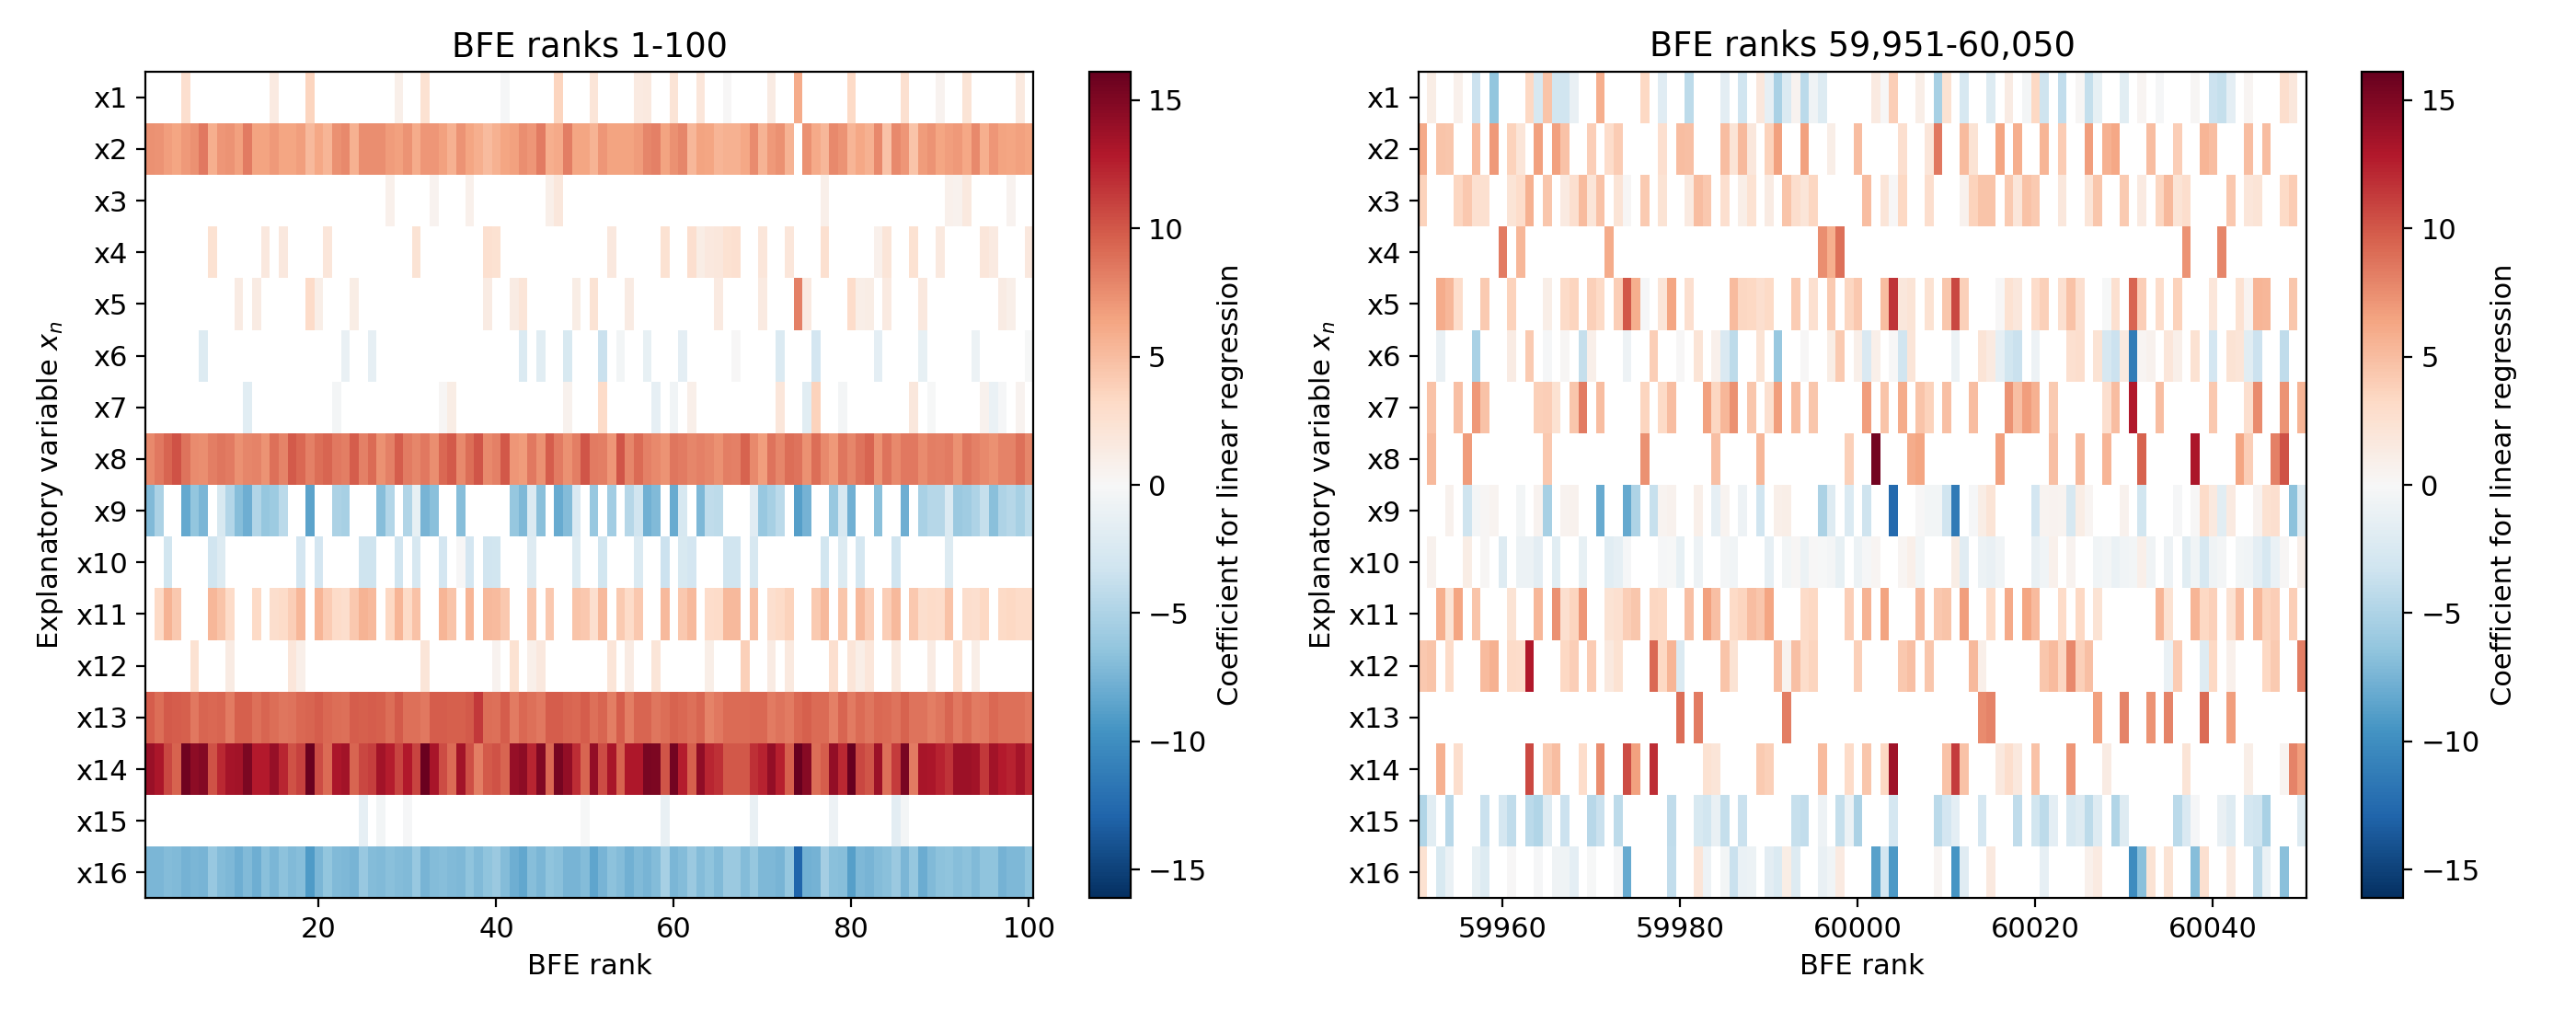

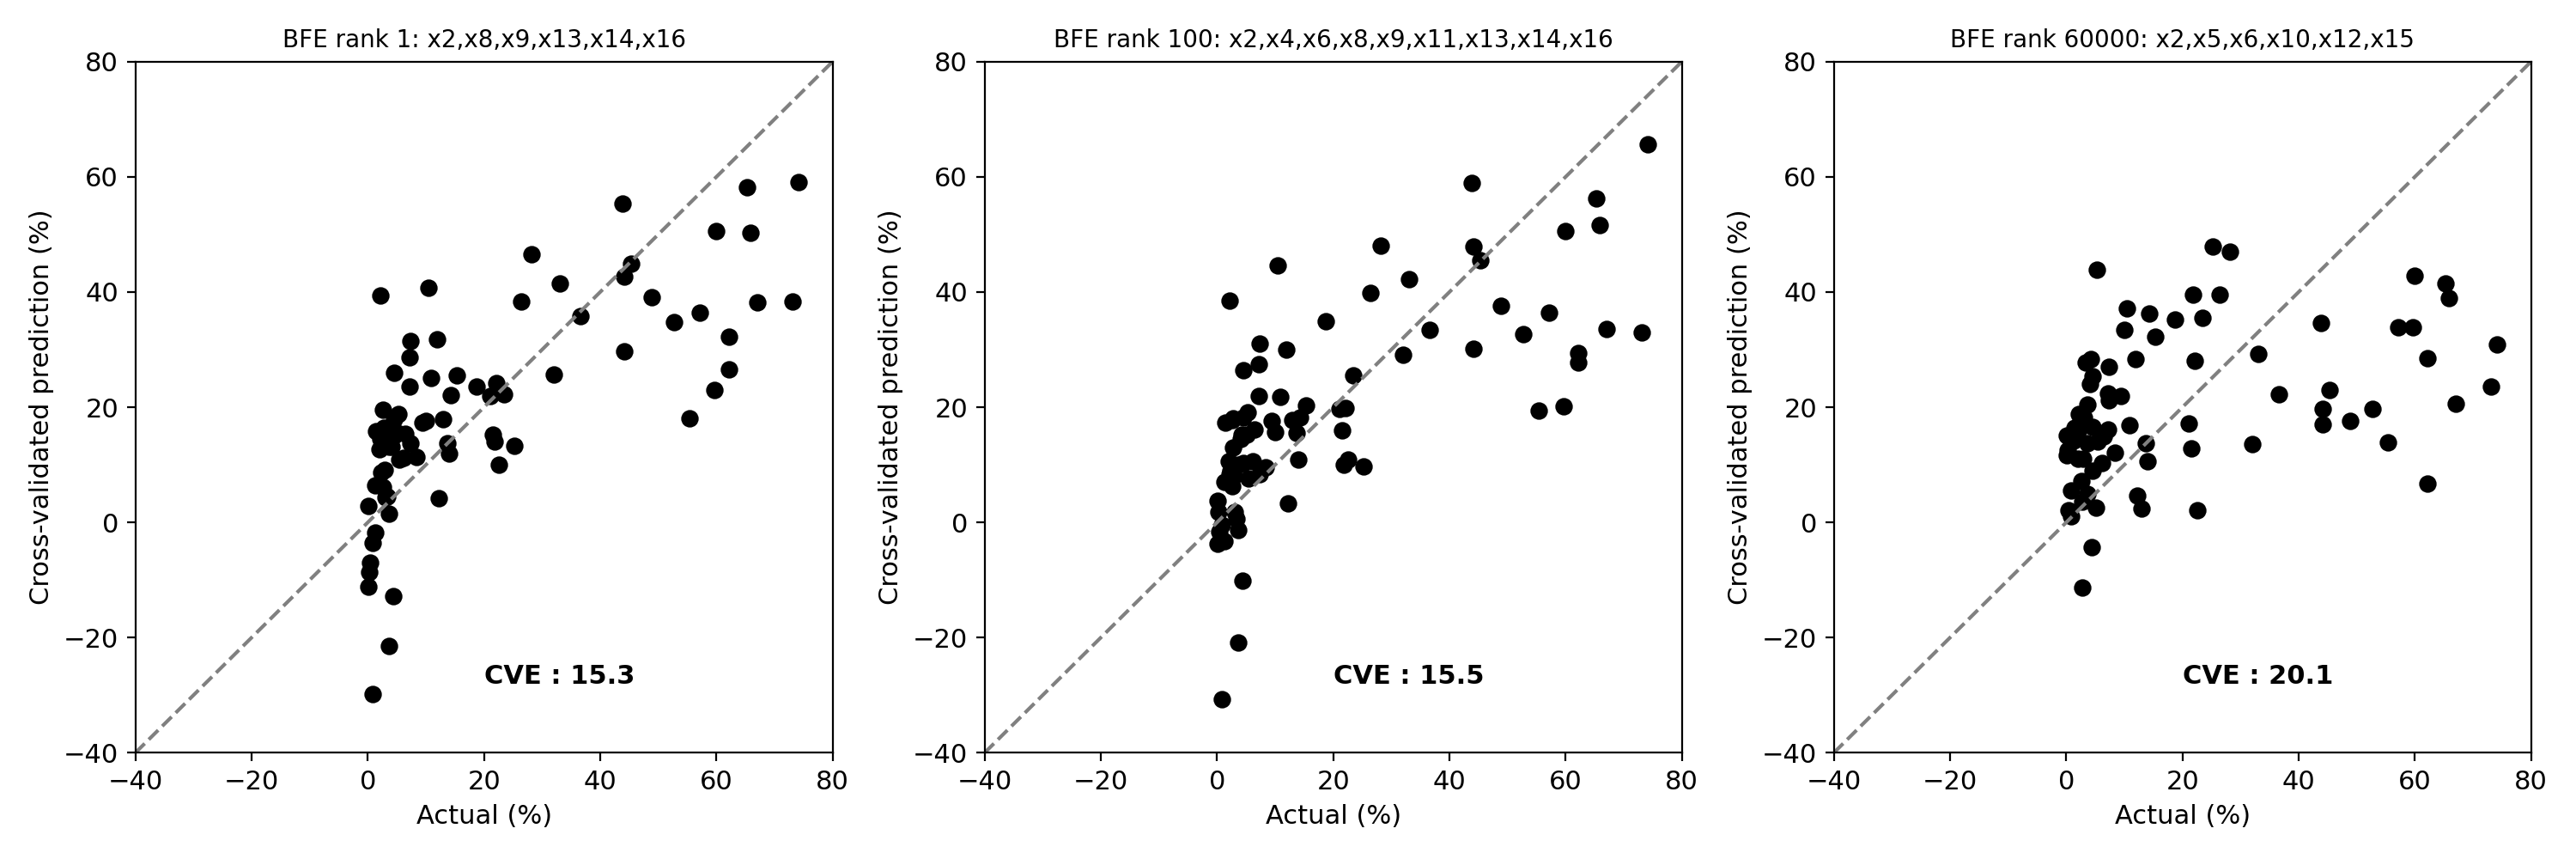

In [3]:
RECOMPUTE_FIG3 = RECOMPUTE_ALL
z = np.load(f"{INTER}/esbma_yield_g30.npz")
ll3, shown, shown_coef = z["loglik"], z["shown_model_index"], z["shown_coef"]
if RECOMPUTE_FIG3:
    r = fit_g30()
    assert (r["shown"] == shown).all()
    print("max |Δ loglik| vs cache = %.2e, max |Δ coef| = %.2e" % (
        np.abs(r["log_likelihoods"] - ll3).max(), np.abs(r["shown_coef"] - shown_coef).max()))
    ll3, shown_coef = r["log_likelihoods"], r["shown_coef"]
order3 = np.argsort(ll3)[::-1]                        # BFE rank 1 = highest marginal likelihood
assert (order3[:100] == shown[:100]).all() and (order3[59950:60050] == shown[100:]).all()
IND = lambda i: ((int(i) >> np.arange(16)) & 1).astype(bool)   # exhbma model index -> indicator
ind_shown = np.array([IND(i) for i in shown])

top_inc = ind_shown[:100].sum(0); pos = ((shown_coef[:100] > 0) & ind_shown[:100]).sum(0); neg = ((shown_coef[:100] < 0) & ind_shown[:100]).sum(0)
print(pd.DataFrame({"var": D.PAPER_NAMES, "in top 100": top_inc, "positive": pos, "negative": neg}).T.to_string(header=False))
consistent = [D.PAPER_NAMES[j] for j in range(16) if top_inc[j] >= 50 and min(pos[j], neg[j]) == 0]
check("Fig 3", "variables in >= 50 of the top-100 models, all with the same sign", consistent,
      ["x2", "x8", "x9", "x11", "x13", "x14", "x16"])

vmax = np.abs(shown_coef[:100]).max()
def weight_diagram(ax, coef, ind, ranks):
    mc = np.ma.masked_where(ind == 0, coef)
    mesh = ax.pcolormesh(np.arange(len(ranks) + 1) + ranks[0] - 0.5, np.arange(17),
                         mc.T[::-1], cmap="RdBu_r", vmin=-vmax, vmax=vmax)
    ax.set_yticks(np.arange(16) + 0.5); ax.set_yticklabels(D.PAPER_NAMES[::-1])
    ax.set_xlabel("BFE rank"); ax.set_ylabel(r"Explanatory variable $x_n$")
    return mesh

fig, axs = plt.subplots(1, 2, figsize=(14, 5.5))
m1 = weight_diagram(axs[0], shown_coef[:100], ind_shown[:100], np.arange(1, 101))
m2 = weight_diagram(axs[1], shown_coef[100:], ind_shown[100:], np.arange(59951, 60051))
axs[0].set_title("BFE ranks 1-100"); axs[1].set_title("BFE ranks 59,951-60,050")
for m, a in ((m1, axs[0]), (m2, axs[1])): fig.colorbar(m, ax=a).set_label("Coefficient for linear regression")
fig.tight_layout(); fig.savefig(f"{FIGS}/Fig3_weight_diagrams.png", dpi=200); plt.close(fig)

print("variables present in all/most of the top-100 models with one sign:",
      {D.PAPER_NAMES[j]: int(top_inc[j]) for j in range(16) if top_inc[j] >= 99 and min(pos[j], neg[j]) == 0})
check("Fig 3", "variables in all 100 top models with the same sign", [D.PAPER_NAMES[j] for j in range(16) if top_inc[j] == 100 and min(pos[j], neg[j]) == 0],
      ["x8", "x13", "x14", "x16"])
check("Fig 3", "x2: number of top-100 models (all positive)", int(pos[1]) if neg[1] == 0 else -1, 99)

# CVE (DoS, Fig 7) of the displayed models
st3 = pd.read_csv(f"{INTER}/fig7_dos_cve_real_states.csv.gz"); cve3 = dict(zip(st3["mask"].astype(np.int64), st3["cve"]))
rank3 = dict(zip(st3["mask"].astype(np.int64), st3["rank"]))
for lab_, sl in (("BFE ranks 1-100", slice(0, 100)), ("BFE ranks 59,951-60,050", slice(100, 200))):
    c_ = np.array([cve3[int(m)] for m in shown[sl]])
    print(f"CVE of {lab_}: median {np.median(c_):.2f}, range {c_.min():.2f}-{c_.max():.2f}")
    exp_ = {"BFE ranks 1-100": (15.57, 15.02, 15.98), "BFE ranks 59,951-60,050": (19.52, 17.63, 20.48)}[lab_]
    check("Fig 3", f"CVE median / min / max, {lab_}", (round(float(np.median(c_)), 2), round(float(c_.min()), 2), round(float(c_.max()), 2)), exp_)

fig, axs = plt.subplots(1, 3, figsize=(15, 5))
expected = {1: (["x2", "x8", "x9", "x13", "x14", "x16"], 15.297, 18),
            100: (["x2", "x4", "x6", "x8", "x9", "x11", "x13", "x14", "x16"], 15.516, 78),
            60000: (["x2", "x5", "x6", "x10", "x12", "x15"], 20.076, 61889)}
for a, rank in zip(axs, (1, 100, 60000)):
    sel = IND(order3[rank - 1]); names = list(np.array(D.PAPER_NAMES)[sel])
    pred, cve = fig3.cv_prediction(X, y, sel)
    mask = int(order3[rank - 1])                       # exhbma model index = DoS bit mask
    assert abs(cve - cve3[mask]) < 1e-12, "CV prediction must reproduce the DoS CVE"
    print(f"BFE rank {rank:>5}: {names}  CVE {cve:.3f} (DoS CVE {cve3[mask]:.3f}, CVE rank {rank3[mask]})")
    a.scatter(y, pred, s=40, c="black")
    a.plot([-40, 80], [-40, 80], "--", c="gray"); a.set_xlim(-40, 80); a.set_ylim(-40, 80)
    a.set_xlabel("Actual (%)"); a.set_ylabel("Cross-validated prediction (%)")
    a.text(0.5, 0.1, f"CVE : {cve:.1f}", transform=a.transAxes, fontweight="bold")
    a.set_title(f"BFE rank {rank}: " + ",".join(names), fontsize=10)
    check("Fig 3", f"model at BFE rank {rank}", names, expected[rank][0])
    check("Fig 3", f"CVE (5-fold, DoS protocol), BFE rank {rank}", round(cve, 3), expected[rank][1], 0.0005)
    check("Fig 3", f"CVE rank of the BFE-rank-{rank} model", int(rank3[mask]), expected[rank][2])
fig.tight_layout(); fig.savefig(f"{FIGS}/Fig3_predictions.png", dpi=200); plt.close(fig)
show(f"{FIGS}/Fig3_weight_diagrams.png"); show(f"{FIGS}/Fig3_predictions.png")

## 2. Fig 4 – Bolasso vs ES-BMA on the real yield data (N = 80)

* **ES-BMA**: all 2<sup>16</sup> models, σ grid `inverse(logspace(-2.5, 2.5, 30))` (original `redo_fp_main.py`,
  output `fp_g30_main.csv`, column `esbma_fp_real80`).
* **Bolasso**: α by 5-fold CV (MSE) on `logspace(-5, 5, 100)`, 100 bootstrap resamples, selection rate = fraction of
  non-zero coefficients (`~/esbma_bolasso_fix/run_fix.py`). The paper uses the *fixed* standardisation (only `std == 0`
  columns unscaled). The original code used `std < 1e-12`, which left x14 (raw values ≈ 10<sup>-39</sup>) unscaled so it
  was never selected; those rates are kept in `fp_g30_main.csv` (`bolasso_rate_real80`) and printed for reference.

Paper: Bolasso > 0.75 for x2, x4, x8, x10, x11, x13, x14, x16; ES-BMA > 0.75 for x2, x8, x13, x14, x16;
mean probability 0.68 (Bolasso) vs 0.55 (ES-BMA), median 0.78 vs 0.39.
*Recompute*: the shared unified ES-BMA fit (≈ 15 s) and Bolasso (< 1 min).

ES-BMA: max |Δ posterior| vs cache = 2.00e-14


Bolasso recomputed in 0 s (alpha = 0.5591), max |Δ rate| = 0.000
paper col  Bolasso (fixed)  Bolasso (orig. std<1e-12)  ES-BMA
   x1  x2             0.38                       0.36   0.322
   x2  x4             0.98                       0.72   0.896
   x3  x5             0.70                       0.82   0.280
   x4  x8             0.85                       0.97   0.385
   x5 x10             0.27                       0.45   0.353
   x6 x14             0.19                       0.26   0.301
   x7 x17             0.45                       0.96   0.318
   x8 x18             0.95                       0.99   0.892
   x9 x26             0.34                       0.99   0.579
  x10 x28             0.90                       0.95   0.392
  x11 x29             1.00                       1.00   0.648
  x12 x31             0.39                       0.47   0.335
  x13 x32             1.00                       1.00   0.995
  x14 x34             1.00                       0.00   0.991
  x15

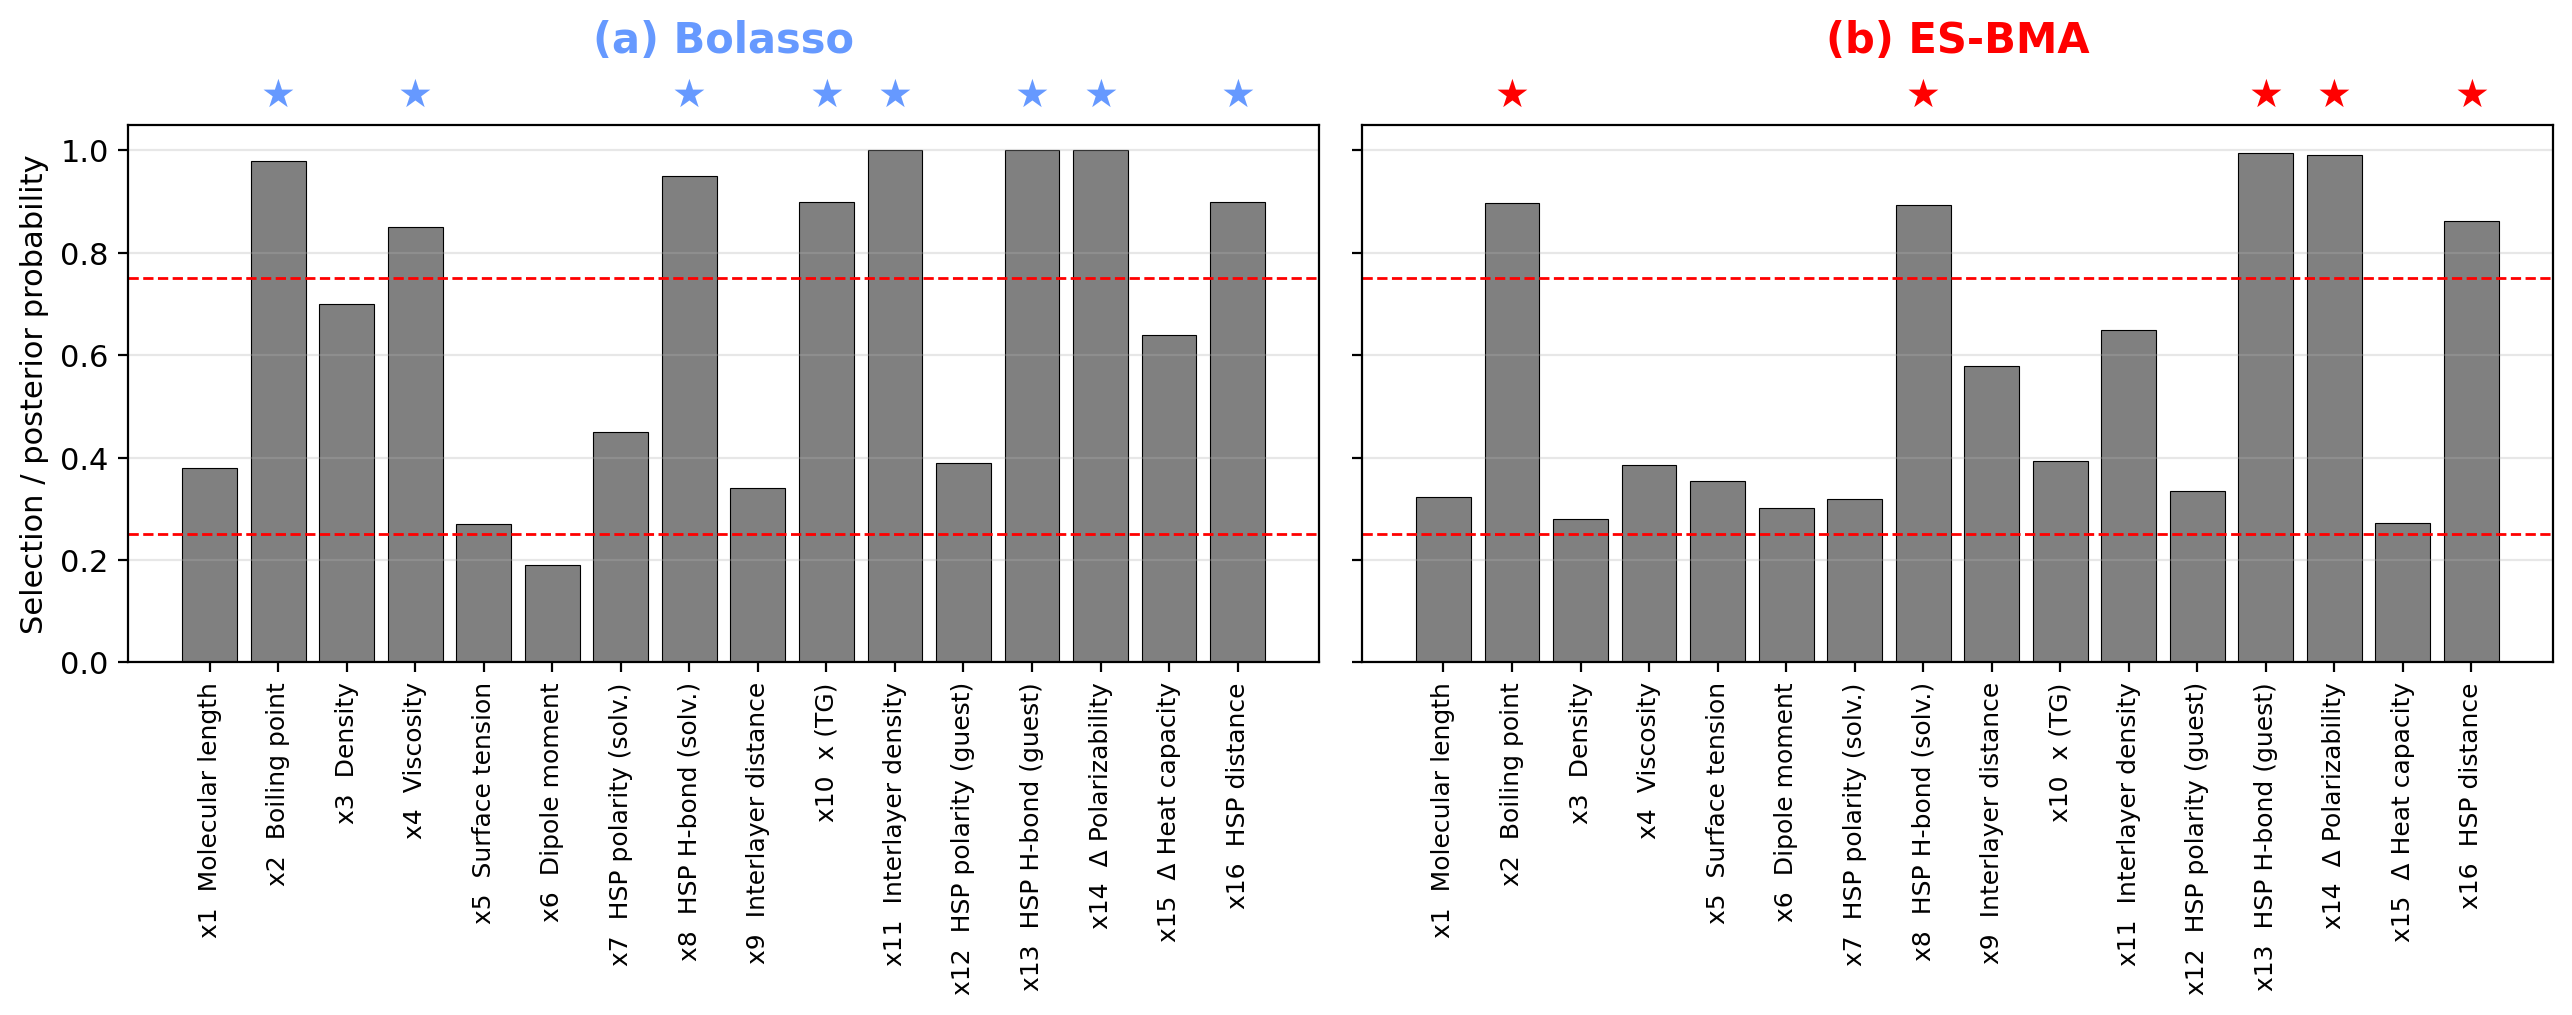

In [4]:
RECOMPUTE_FIG4 = RECOMPUTE_ALL
fp = pd.read_csv(f"{INTER}/fig4_fp_g30_main.csv"); fx = pd.read_csv(f"{INTER}/fig4_bolasso_rate_real80_fixed.csv")
assert list(fp.col) == D.YIELD_COLS and list(fx.col) == D.YIELD_COLS
esb4 = fp["esbma_fp_real80"].to_numpy(); bol4 = fx["bolasso_rate_real80_fixed"].to_numpy()
if RECOMPUTE_FIG4:
    r = fit_g30()
    print("ES-BMA: max |Δ posterior| vs cache = %.2e" % np.abs(r["feature_posteriors"] - esb4).max())
    t = time.time(); rate, rows, a = bolasso.bolasso_rate(X, y, D.YIELD_COLS, nb=100, seed=43, guard="zero")
    print("Bolasso recomputed in %.0f s (alpha = %.4g), max |Δ rate| = %.3f" % (time.time() - t, a, np.abs(rate - bol4).max()))
    pd.DataFrame({"col": D.YIELD_COLS, "esbma": r["feature_posteriors"], "bolasso_fixed": rate}).to_csv(f"{RES}/fig4.csv", index=False)
    pd.DataFrame(rows).to_csv(f"{RES}/fig7_bolasso_supports_real_fixed.csv", index=False)
    esb4, bol4 = r["feature_posteriors"], rate

print(pd.DataFrame({"paper": D.PAPER_NAMES, "col": D.YIELD_COLS, "Bolasso (fixed)": bol4.round(2),
                    "Bolasso (orig. std<1e-12)": fp["bolasso_rate_real80"].round(2), "ES-BMA": esb4.round(3)}).to_string(index=False))
sel_b = [D.PAPER_NAMES[i] for i in range(16) if bol4[i] > 0.75]; sel_e = [D.PAPER_NAMES[i] for i in range(16) if esb4[i] > 0.75]
check("Fig 4", "Bolasso features > 0.75", sel_b, ["x2", "x4", "x8", "x10", "x11", "x13", "x14", "x16"])
check("Fig 4", "ES-BMA features > 0.75", sel_e, ["x2", "x8", "x13", "x14", "x16"])
check("Fig 4 text", "mean Bolasso probability", round(float(bol4.mean()), 3), 0.68, 0.0051)
check("Fig 4 text", "mean ES-BMA posterior", round(float(esb4.mean()), 3), 0.55, 0.0051)
check("Fig 4 text", "median Bolasso probability", round(float(np.median(bol4)), 3), 0.78, 0.0051)
check("Fig 4 text", "median ES-BMA posterior", round(float(np.median(esb4)), 3), 0.39, 0.0051)

LBL = [f"x{i+1}  {n}" for i, n in enumerate(D.DESCRIPTION)]
def bars(ax, v, cols, title, star_col, title_col="black"):
    ax.bar(range(16), v, color=cols, edgecolor="black", linewidth=0.4)
    for i, yv in enumerate(v):
        if yv >= 0.75: ax.text(i, 1.07, "★", ha="center", va="bottom", color=star_col, fontsize=14, clip_on=False, fontfamily="DejaVu Sans")
    for t_ in (0.25, 0.75): ax.axhline(t_, color="red", ls="--", lw=1)
    ax.set_xticks(range(16)); ax.set_xticklabels(LBL, rotation=90, fontsize=9)
    ax.set_ylim(0, 1.05); ax.set_title(title, fontsize=15, fontweight="bold", pad=26, color=title_col); ax.grid(axis="y", alpha=.3)
fig, ax = plt.subplots(1, 2, figsize=(13, 5.2), sharey=True)
bars(ax[0], bol4, [GRAY] * 16, "(a) Bolasso", BLUE, BLUE); bars(ax[1], esb4, [GRAY] * 16, "(b) ES-BMA", RED, RED)
ax[0].set_ylabel("Selection / posterior probability")
fig.tight_layout(); fig.savefig(f"{FIGS}/Fig4_real80.png", dpi=200, bbox_inches="tight"); plt.close(fig)
show(f"{FIGS}/Fig4_real80.png")

## 3. Fig 5 – joint posterior of (σ<sub>ε</sub>, σ<sub>w</sub>) at N = 80 (and its convergence, Fig S2)

p(σ<sub>ε</sub>, σ<sub>w</sub> | D) ∝ p(σ<sub>ε</sub>) p(σ<sub>w</sub>) Σ<sub>models</sub> p(model) p(y | X, model, σ<sub>ε</sub>, σ<sub>w</sub>)
on the unified 30×30 grid (logic of `notebook/experiment1/montage_conv.py`). N = 80 uses all samples; for the
convergence panel (Fig S2) N = 10, 20, …, 70 samples are drawn without replacement with `default_rng(1)`.

Expected: MAP log<sub>10</sub>σ<sub>ε</sub> = 1.12, log<sub>10</sub>σ<sub>w</sub> = 0.78; posterior standard deviations
0.04 and 0.15 (the grid spacing is 0.17 in log<sub>10</sub>, so σ<sub>ε</sub> is resolved to within one grid cell); the MAP
is at (1.12, 0.78) for N = 50, 60 and 80 and one grid point higher in σ<sub>w</sub> (0.95) for N = 70.
*Recompute*: N = 80 comes from the shared fit; the full recomputation adds 7 fits (≈ 1.5 min; skipped with `ESBMA_QUICK=1`).

N=80: max |Δ posterior probability| vs cache (float32) = 3.2e-08
N=10  MAP (log10 s_eps, log10 s_w) = (-2.50,  1.12)   sd = (1.813, 1.641)   max cell mass 0.09
N=20  MAP (log10 s_eps, log10 s_w) = ( 1.47, -2.50)   sd = (0.115, 0.795)   max cell mass 0.22
N=30  MAP (log10 s_eps, log10 s_w) = ( 1.29, -2.50)   sd = (0.035, 0.444)   max cell mass 0.31
N=40  MAP (log10 s_eps, log10 s_w) = ( 1.29, -2.50)   sd = (0.059, 0.886)   max cell mass 0.26
N=50  MAP (log10 s_eps, log10 s_w) = ( 1.12,  0.78)   sd = (0.091, 1.319)   max cell mass 0.18
N=60  MAP (log10 s_eps, log10 s_w) = ( 1.12,  0.78)   sd = (0.086, 1.035)   max cell mass 0.18
N=70  MAP (log10 s_eps, log10 s_w) = ( 1.12,  0.95)   sd = (0.073, 0.186)   max cell mass 0.31
N=80  MAP (log10 s_eps, log10 s_w) = ( 1.12,  0.78)   sd = (0.038, 0.145)   max cell mass 0.46
[OK ] Fig 5: MAP (log10 s_eps, log10 s_w), N = 80 = (1.12, 0.78)  (expected: (1.12, 0.78))
[OK ] Fig 5: posterior sd of log10 s_eps, N = 80 = 0.04  (expected: 0.04)
[OK ] Fig 

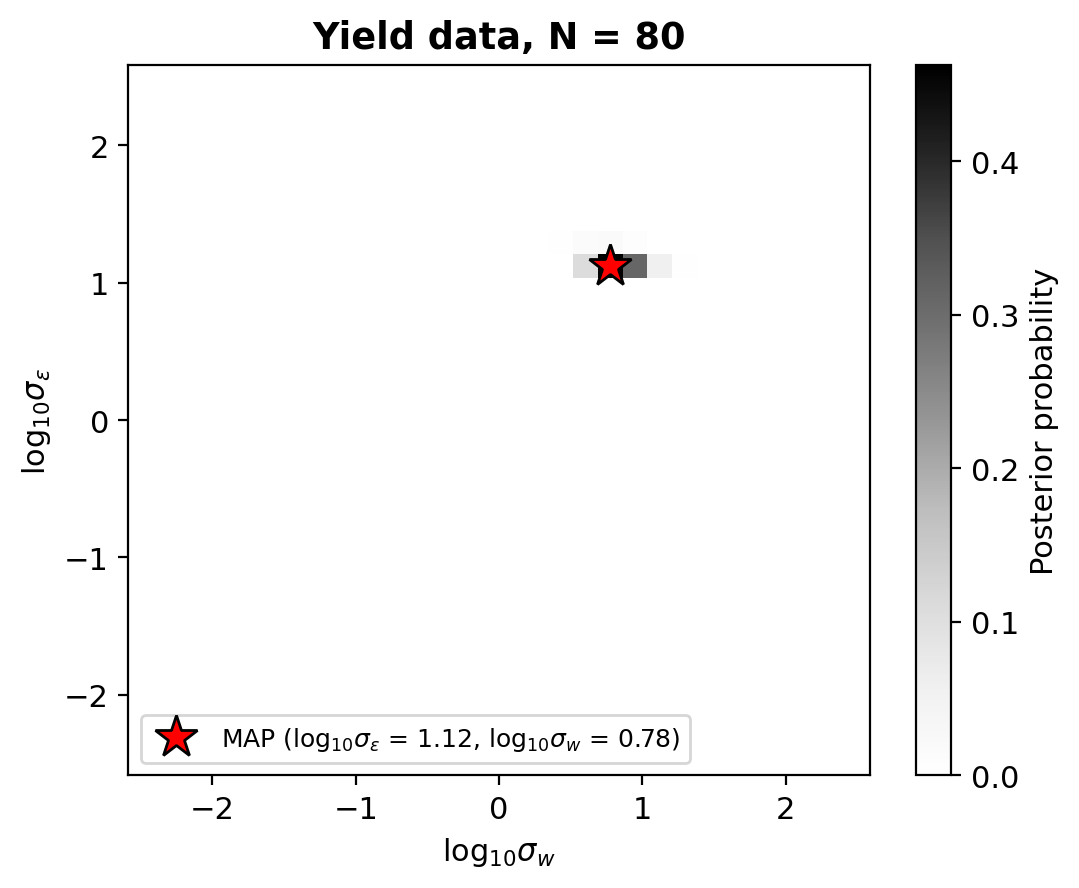

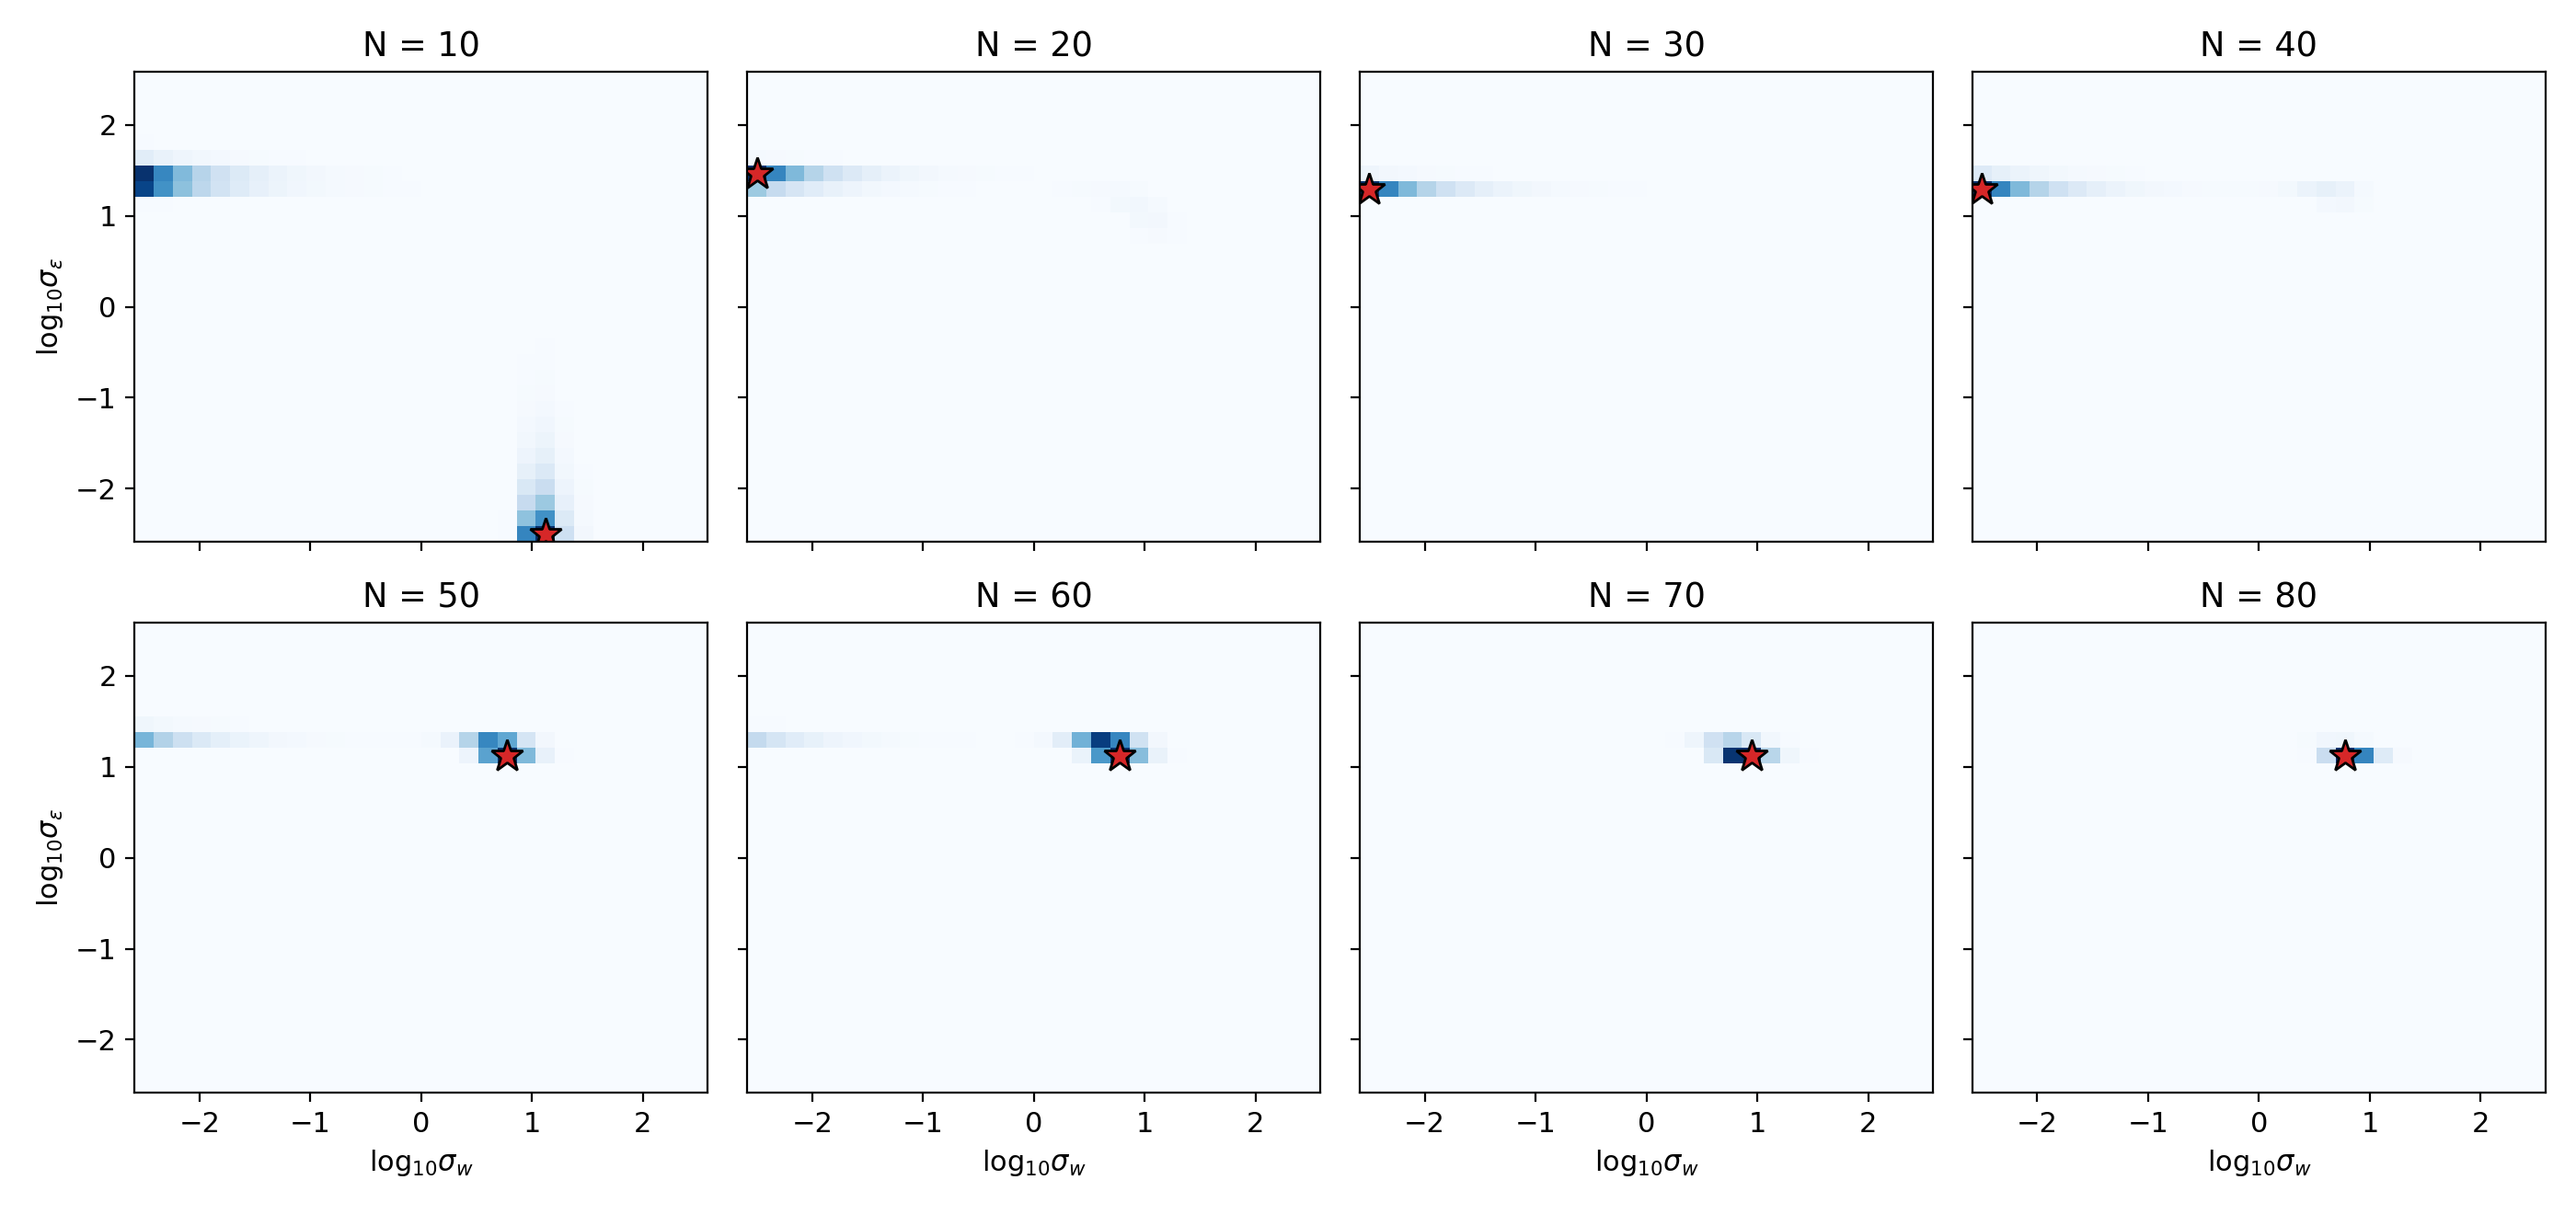

In [5]:
RECOMPUTE_FIG5 = RECOMPUTE_ALL
zp = np.load(f"{INTER}/fig5_post_real_g30.npz"); Ns = list(zp["N"]); k = Ns.index(80)
le, lw, DIST = zp["log_eps"], zp["log_w"], zp["dist"].astype(float)
if RECOMPUTE_FIG5:
    todo = [80] if QUICK else Ns
    for N in todo:
        if N == 80:
            d = fit_g30()["sigma_log_posterior"]
        else:
            idx = np.random.default_rng(1).choice(len(X), size=N, replace=False)
            d = (esbma.fit_exhaustive(X[idx], y[idx], *GRID, n_jobs=N_JOBS) if USE_EXHBMA
                 else FE.fit_fast_full(X[idx], y[idx], *GRID))["sigma_log_posterior"]
        kk = Ns.index(N); pc = np.exp(DIST[kk] - DIST[kk].max()); pc /= pc.sum(); pr = np.exp(d - d.max()); pr /= pr.sum()
        print("N=%d: max |Δ posterior probability| vs cache (float32) = %.1e" % (N, np.abs(pr - pc).max()))
        DIST[kk] = d
sd = lambda w, x: np.sqrt((w * (x - (w * x).sum()) ** 2).sum())
maps = {}
for kk, N in enumerate(Ns):
    p = np.exp(DIST[kk] - DIST[kk].max()); p /= p.sum(); i, j = np.unravel_index(np.argmax(p), p.shape)
    maps[N] = (round(float(le[i]), 2), round(float(lw[j]), 2))
    print("N=%2d  MAP (log10 s_eps, log10 s_w) = (%5.2f, %5.2f)   sd = (%.3f, %.3f)   max cell mass %.2f"
          % (N, le[i], lw[j], sd(p.sum(1), le), sd(p.sum(0), lw), p.max()))
p = np.exp(DIST[k] - DIST[k].max()); p /= p.sum(); i, j = np.unravel_index(np.argmax(p), p.shape)
check("Fig 5", "MAP (log10 s_eps, log10 s_w), N = 80", maps[80], (1.12, 0.78))
check("Fig 5", "posterior sd of log10 s_eps, N = 80", round(sd(p.sum(1), le), 2), 0.04, 0.005)
check("Fig 5", "posterior sd of log10 s_w, N = 80", round(sd(p.sum(0), lw), 2), 0.15, 0.005)
check("Fig S2", "MAP for N = 50, 60, 80", [maps[50], maps[60], maps[80]], [(1.12, 0.78)] * 3)
fig, ax = plt.subplots(figsize=(5.6, 4.6))
m = ax.pcolormesh(lw, le, p, shading="auto", cmap="Greys")
ax.plot(lw[j], le[i], "*", color="#ff0000", ms=16, mec="k",
        label=f"MAP ($\\log_{{10}}\\sigma_\\varepsilon$ = {le[i]:.2f}, $\\log_{{10}}\\sigma_w$ = {lw[j]:.2f})")
ax.set_xlabel(r"$\log_{10}\sigma_w$"); ax.set_ylabel(r"$\log_{10}\sigma_\varepsilon$"); ax.set_title("Yield data, N = 80", fontweight="bold")
fig.colorbar(m, ax=ax).set_label("Posterior probability"); ax.legend(loc="lower left", fontsize=9)
fig.tight_layout(); fig.savefig(f"{FIGS}/Fig5_posterior_n80.png", dpi=200, bbox_inches="tight"); plt.close(fig)
fig, axs = plt.subplots(2, 4, figsize=(14, 6.6), sharex=True, sharey=True)
for kk, a in enumerate(axs.flat):
    q = np.exp(DIST[kk] - DIST[kk].max()); q /= q.sum(); a.pcolormesh(lw, le, q, shading="auto", cmap="Blues")
    ii, jj = np.unravel_index(np.argmax(q), q.shape); a.plot(lw[jj], le[ii], "*", color="#d62728", ms=13, mec="k")
    a.set_title(f"N = {Ns[kk]}")
for a in axs[1]: a.set_xlabel(r"$\log_{10}\sigma_w$")
for a in axs[:, 0]: a.set_ylabel(r"$\log_{10}\sigma_\varepsilon$")
fig.tight_layout(); fig.savefig(f"{FIGS}/FigS2_convergence_real.png", dpi=200); plt.close(fig)
show(f"{FIGS}/Fig5_posterior_n80.png"); show(f"{FIGS}/FigS2_convergence_real.png")

## 4. Fig 6 – synthetic target y = 1.0·x8 + ε

The 16 real descriptors of the 80 samples are kept; the target is y = 1.0·z(x8) + ε with R² = 0.95 (σ = 0.229),
paper x8 = column `x18` (solvent HSP hydrogen-bonding term), 30 noise realisations with `default_rng(20260831 + r)`
(identical targets to the original synthetic study). Both methods are applied **exactly as on the real data in Fig 4**:
ES-BMA with the unified exhbma setting (all 65,536 models, including single-descriptor and null models) and Bolasso
(fixed standardisation, α by 5-fold CV, 100 bootstraps) – function `synth.run_rep_unified`.
Panel (a): realisation #26; panel (b): descriptors other than x8 above 0.75 per run, split into the other solvent
descriptors (x1–x7) and the unrelated interlayer / interaction descriptors (x9–x16).

Expected: Bolasso 0.97 false positives per run (0.30 solvent + 0.67 unrelated; ≥ 1 false positive in 19 of 30 runs; mean
probability 0.26 for solvent and 0.30 for unrelated descriptors); ES-BMA 0.03 per run (1 of 30 runs: x11 = 0.82 in
realisation #3; mean probability of false descriptors 0.06 / 0.07). #26: Bolasso x5 = 0.94 (solvent), x13 = 0.77 and
x15 = 0.96 (unrelated); ES-BMA all others ≤ 0.09.
*Recompute*: ≈ 10 s ES-BMA + a few s Bolasso per realisation, ≈ 6 min for 30; `ESBMA_QUICK=1` → #26 only.

recomputed 1 realisation(s) in 10 s
max |Δ ES-BMA posterior| = 1.68e-14 ; max |Δ Bolasso rate| = 0.000
Bolasso FP/run: {'solv': 0.3, 'other': 0.67}  ES-BMA FP/run: {'solv': 0.0, 'other': 0.03}
[OK ] Fig 6: Bolasso false positives per run (total) = 0.97  (expected: 0.97)
[OK ] Fig 6: Bolasso FP per run, solvent descriptors = 0.3  (expected: 0.3)
[OK ] Fig 6: Bolasso FP per run, unrelated descriptors = 0.67  (expected: 0.67)
[OK ] Fig 6: Bolasso runs with a false positive = 19  (expected: 19)
[OK ] Fig 6: Bolasso mean probability, solvent / unrelated = (0.26, 0.3)  (expected: (0.26, 0.3))
[OK ] Fig 6: ES-BMA false positives per run = 0.03  (expected: 0.03)
[OK ] Fig 6: ES-BMA runs with a false positive = 1  (expected: 1)
[OK ] Fig 6: ES-BMA mean probability, solvent / unrelated = (0.06, 0.07)  (expected: (0.06, 0.07))
[OK ] Fig 6: realisation #26, Bolasso > 0.75 = {'x5': 0.94, 'x8': 1.0, 'x13': 0.77, 'x15': 0.96}  (expected: {'x5': 0.94, 'x8': 1.0, 'x13': 0.77, 'x15': 0.96})
[OK ] Fig 6:

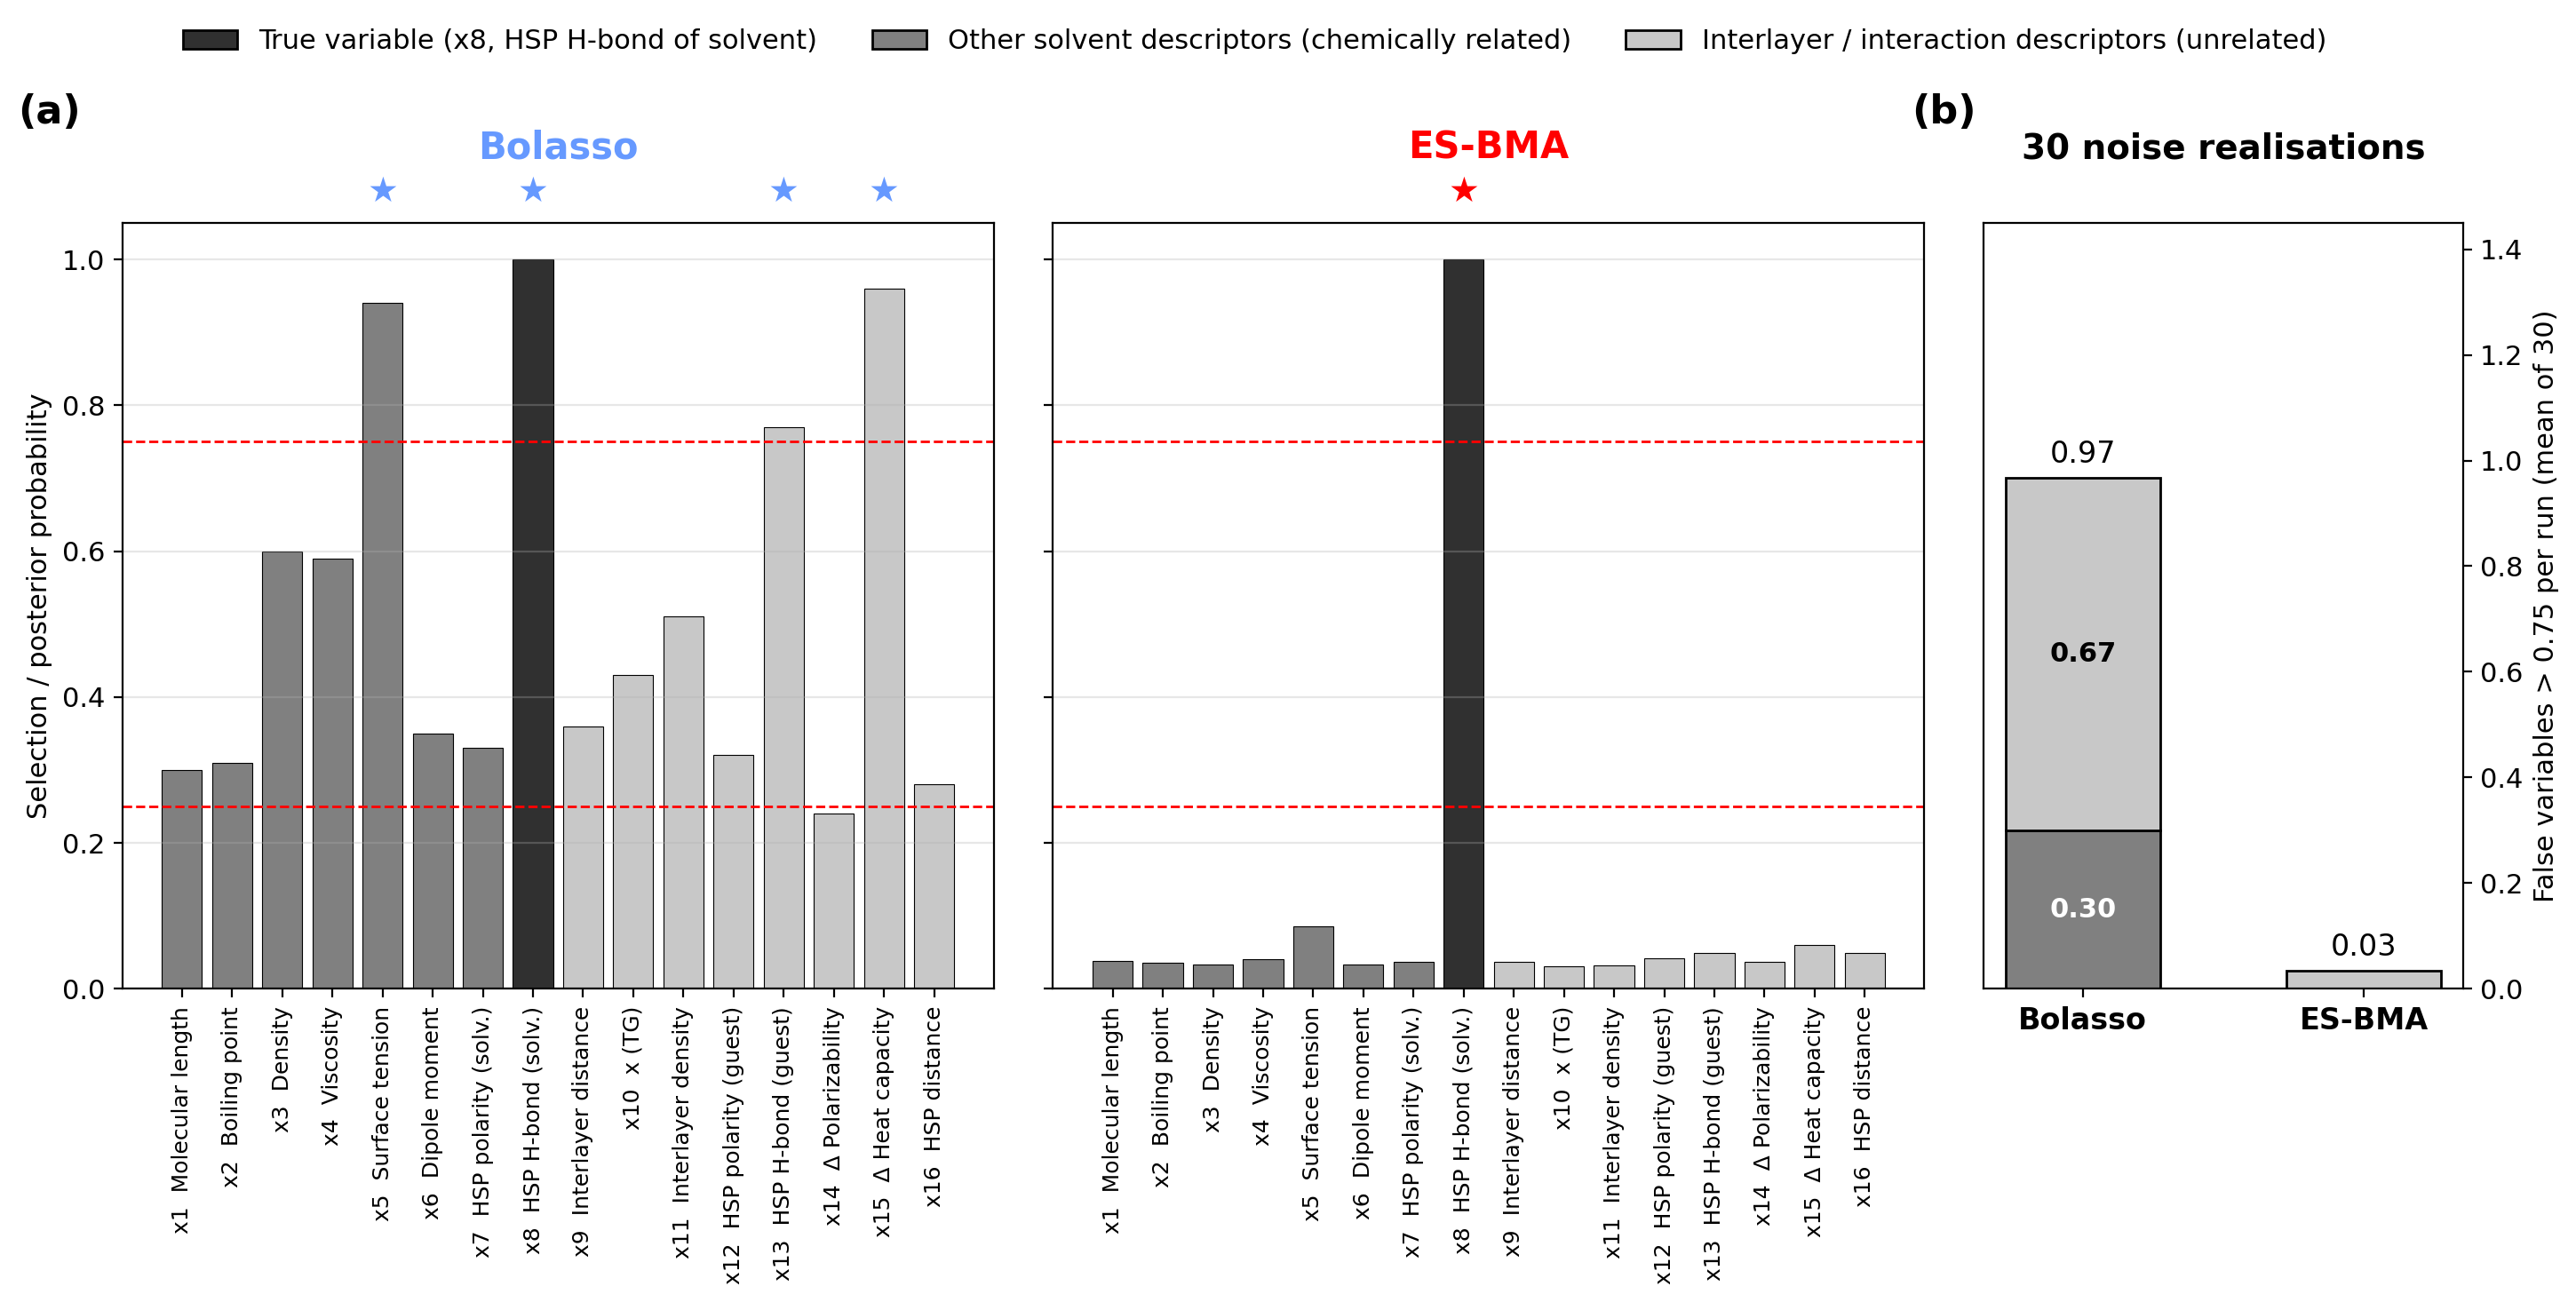

In [6]:
RECOMPUTE_FIG6 = RECOMPUTE_ALL
S = json.load(open(f"{INTER}/fig6_synth_x18_r095_30reps_g30.json"))
assert S["names"] == D.YIELD_COLS and S["j_true"] == 7
BF, PI = np.array(S["bolasso_rate"]), np.array(S["esbma_fp"])        # (30 realisations, 16)
if RECOMPUTE_FIG6:
    reps = [26] if QUICK else list(range(30)); t = time.time(); new = []
    for rr in reps:
        b, e, _ = synth.run_rep_unified(X, D.YIELD_COLS, rr, n_jobs=N_JOBS, use_exhbma=USE_EXHBMA); new.append((b, e))
    print("recomputed %d realisation(s) in %.0f s" % (len(reps), time.time() - t))
    bf_new, pi_new = np.array([o[0] for o in new]), np.array([o[1] for o in new])
    print("max |Δ ES-BMA posterior| = %.2e ; max |Δ Bolasso rate| = %.3f" % (np.abs(pi_new - PI[reps]).max(), np.abs(bf_new - BF[reps]).max()))
    json.dump({"reps": reps, "bolasso_rate": bf_new.tolist(), "esbma_fp": pi_new.tolist()}, open(f"{RES}/fig6.json", "w"))
    BF[reps], PI[reps] = bf_new, pi_new

J, SOLV, OTH = 7, list(range(0, 7)), list(range(8, 16))
cat = lambda i: "true" if i == J else ("solv" if i in SOLV else "other")
def fp_counts(M):
    return {"solv": float((M[:, SOLV] >= 0.75).sum(1).mean()), "other": float((M[:, OTH] >= 0.75).sum(1).mean())}
cb, ce = fp_counts(BF), fp_counts(PI)
runs_b = int(((BF[:, SOLV + OTH] >= 0.75).sum(1) > 0).sum()); runs_e = int(((PI[:, SOLV + OTH] >= 0.75).sum(1) > 0).sum())
print("Bolasso FP/run:", {k: round(v, 2) for k, v in cb.items()}, " ES-BMA FP/run:", {k: round(v, 2) for k, v in ce.items()})
check("Fig 6", "Bolasso false positives per run (total)", round(cb["solv"] + cb["other"], 2), 0.97, 0.005)
check("Fig 6", "Bolasso FP per run, solvent descriptors", round(cb["solv"], 2), 0.30, 0.005)
check("Fig 6", "Bolasso FP per run, unrelated descriptors", round(cb["other"], 2), 0.67, 0.005)
check("Fig 6", "Bolasso runs with a false positive", runs_b, 19)
check("Fig 6", "Bolasso mean probability, solvent / unrelated", (round(BF[:, SOLV].mean(), 2), round(BF[:, OTH].mean(), 2)), (0.26, 0.30))
check("Fig 6", "ES-BMA false positives per run", round(ce["solv"] + ce["other"], 2), 0.03, 0.005)
check("Fig 6", "ES-BMA runs with a false positive", runs_e, 1)
check("Fig 6", "ES-BMA mean probability, solvent / unrelated", (round(PI[:, SOLV].mean(), 2), round(PI[:, OTH].mean(), 2)), (0.06, 0.07))
r26b, r26e = BF[26], PI[26]
sel26 = {D.PAPER_NAMES[i]: round(float(r26b[i]), 2) for i in range(16) if r26b[i] >= 0.75}
check("Fig 6", "realisation #26, Bolasso > 0.75", sel26, {"x5": 0.94, "x8": 1.0, "x13": 0.77, "x15": 0.96})
check("Fig 6", "realisation #26, ES-BMA max over x != x8", round(float(np.delete(r26e, J).max()), 2), 0.09, 0.005)

LBL6 = [f"x{i+1}  {n}" for i, n in enumerate(D.DESCRIPTION)]
COL = {"true": "#303030", "solv": "#808080", "other": "#c8c8c8"}
LEG = {"true": "True variable (x8, HSP H-bond of solvent)", "solv": "Other solvent descriptors (chemically related)",
       "other": "Interlayer / interaction descriptors (unrelated)"}
fig = plt.figure(figsize=(17, 5.6)); gs = fig.add_gridspec(1, 3, width_ratios=[1, 1, 0.55], wspace=0.08)
a1 = fig.add_subplot(gs[0]); a2 = fig.add_subplot(gs[1], sharey=a1); a3 = fig.add_subplot(gs[2])
cols6 = [COL[cat(i)] for i in range(16)]
bars(a1, r26b, cols6, "Bolasso", BLUE, BLUE); bars(a2, r26e, cols6, "ES-BMA", RED, RED)
a1.text(-0.12, 1.13, "(a)", transform=a1.transAxes, fontsize=16, fontweight="bold")
plt.setp(a2.get_yticklabels(), visible=False); a1.set_ylabel("Selection / posterior probability")
for xi, c in enumerate((cb, ce)):
    bot = 0
    for kk in ("solv", "other"):
        h = c[kk]; a3.bar(xi, h, bottom=bot, color=COL[kk], edgecolor="black", width=.55)
        if h > 0.05: a3.text(xi, bot + h / 2, f"{h:.2f}", ha="center", va="center", color="white" if kk == "solv" else "black", fontweight="bold")
        bot += h
    a3.text(xi, bot + .03, f"{bot:.2f}", ha="center", fontsize=12)
a3.set_xticks([0, 1]); a3.set_xticklabels(["Bolasso", "ES-BMA"], fontsize=12, fontweight="bold"); a3.set_ylim(0, 1.45)
a3.set_ylabel("False variables > 0.75 per run (mean of 30)"); a3.set_title("30 noise realisations", fontsize=14, fontweight="bold", pad=26)
a3.yaxis.set_label_position("right"); a3.yaxis.tick_right()
a3.text(-0.15, 1.13, "(b)", transform=a3.transAxes, fontsize=16, fontweight="bold")
fig.legend(handles=[Patch(facecolor=COL[kk], edgecolor="black", label=LEG[kk]) for kk in COL], loc="upper center", ncol=3,
           frameon=False, bbox_to_anchor=(.5, 1.10), fontsize=11)
fig.savefig(f"{FIGS}/Fig6_synthetic_x8.png", dpi=200, bbox_inches="tight"); plt.close(fig)
show(f"{FIGS}/Fig6_synthetic_x8.png")

## 5. Fig 7 – density of states (DoS) of the cross-validation error

For each of the 65,535 non-empty descriptor subsets: 5-fold CVE (`KFold(5, shuffle=True, random_state=43)`, train-fold
standardisation, OLS, mean held-out RMSE) – `run_dos_cve.py`. Compared with
(i) the 100 bootstrap models of Bolasso (fixed standardisation; same run as Fig 4),
(ii) Bolasso with the α whose full-data support minimises the CVE (`bolasso_cveopt`), and
(iii) the 100 models of highest marginal likelihood (lowest BFE) of the unified ES-BMA fit.

Paper: best CVE 15.02 (x2, x8, x10, x11, x13, x14, x16); Bolasso: 79 distinct models, mean size 10.9, best CVE rank 19,
median rank 1,906, 6 of them in the CVE top 100; CVE-optimal-α Bolasso: 67 distinct, 6 in the top 100;
unified ES-BMA: 44 of its top 100 are in the CVE top 100; the lowest-BFE model {x2, x8, x9, x13, x14, x16} has CVE rank 18,
the lowest-CVE model has BFE rank 3, and the five-feature model {x2, x8, x13, x14, x16} has CVE rank 64 and BFE rank 38.
*Recompute*: DoS ≈ 3 CPU-min (parallel); the shared ES-BMA fit; Bolasso ≈ 1 min.

DoS recomputed in 4 s; max |Δ CVE| = 3.55e-15


max |Δ loglik| (unified fit) = 2.84e-13


CVE-optimal Bolasso recomputed in 0 s (alpha = 0.8902)
identical bootstrap supports: Bolasso True | CVE-opt Bolasso True
[OK ] Fig 7: lowest CVE = 15.02  (expected: 15.02)
[OK ] Fig 7: features of lowest-CVE model = ['x2', 'x8', 'x10', 'x11', 'x13', 'x14', 'x16']  (expected: ['x2', 'x8', 'x10', 'x11', 'x13', 'x14', 'x16'])
[OK ] Fig 7: Bolasso distinct models = 79  (expected: 79)
[OK ] Fig 7: Bolasso mean model size = 10.9  (expected: 10.9)
[OK ] Fig 7: Bolasso best CVE rank = 19  (expected: 19)
[OK ] Fig 7: Bolasso median CVE rank = 1906  (expected: 1906)
[OK ] Fig 7: Bolasso models in CVE top 100 = 6  (expected: 6)
[OK ] Fig 7: CVE-opt Bolasso distinct models = 67  (expected: 67)
[OK ] Fig 7: CVE-opt Bolasso models in CVE top 100 = 6  (expected: 6)
[OK ] Fig 7: ES-BMA top-100 models in CVE top 100 = 44  (expected: 44)
[OK ] Fig 7: CVE rank of the lowest-BFE model = 18  (expected: 18)
[OK ] Fig 7: BFE rank of the lowest-CVE model = 3  (expected: 3)
[OK ] Fig 7: CVE rank of {x2,x8,x13,

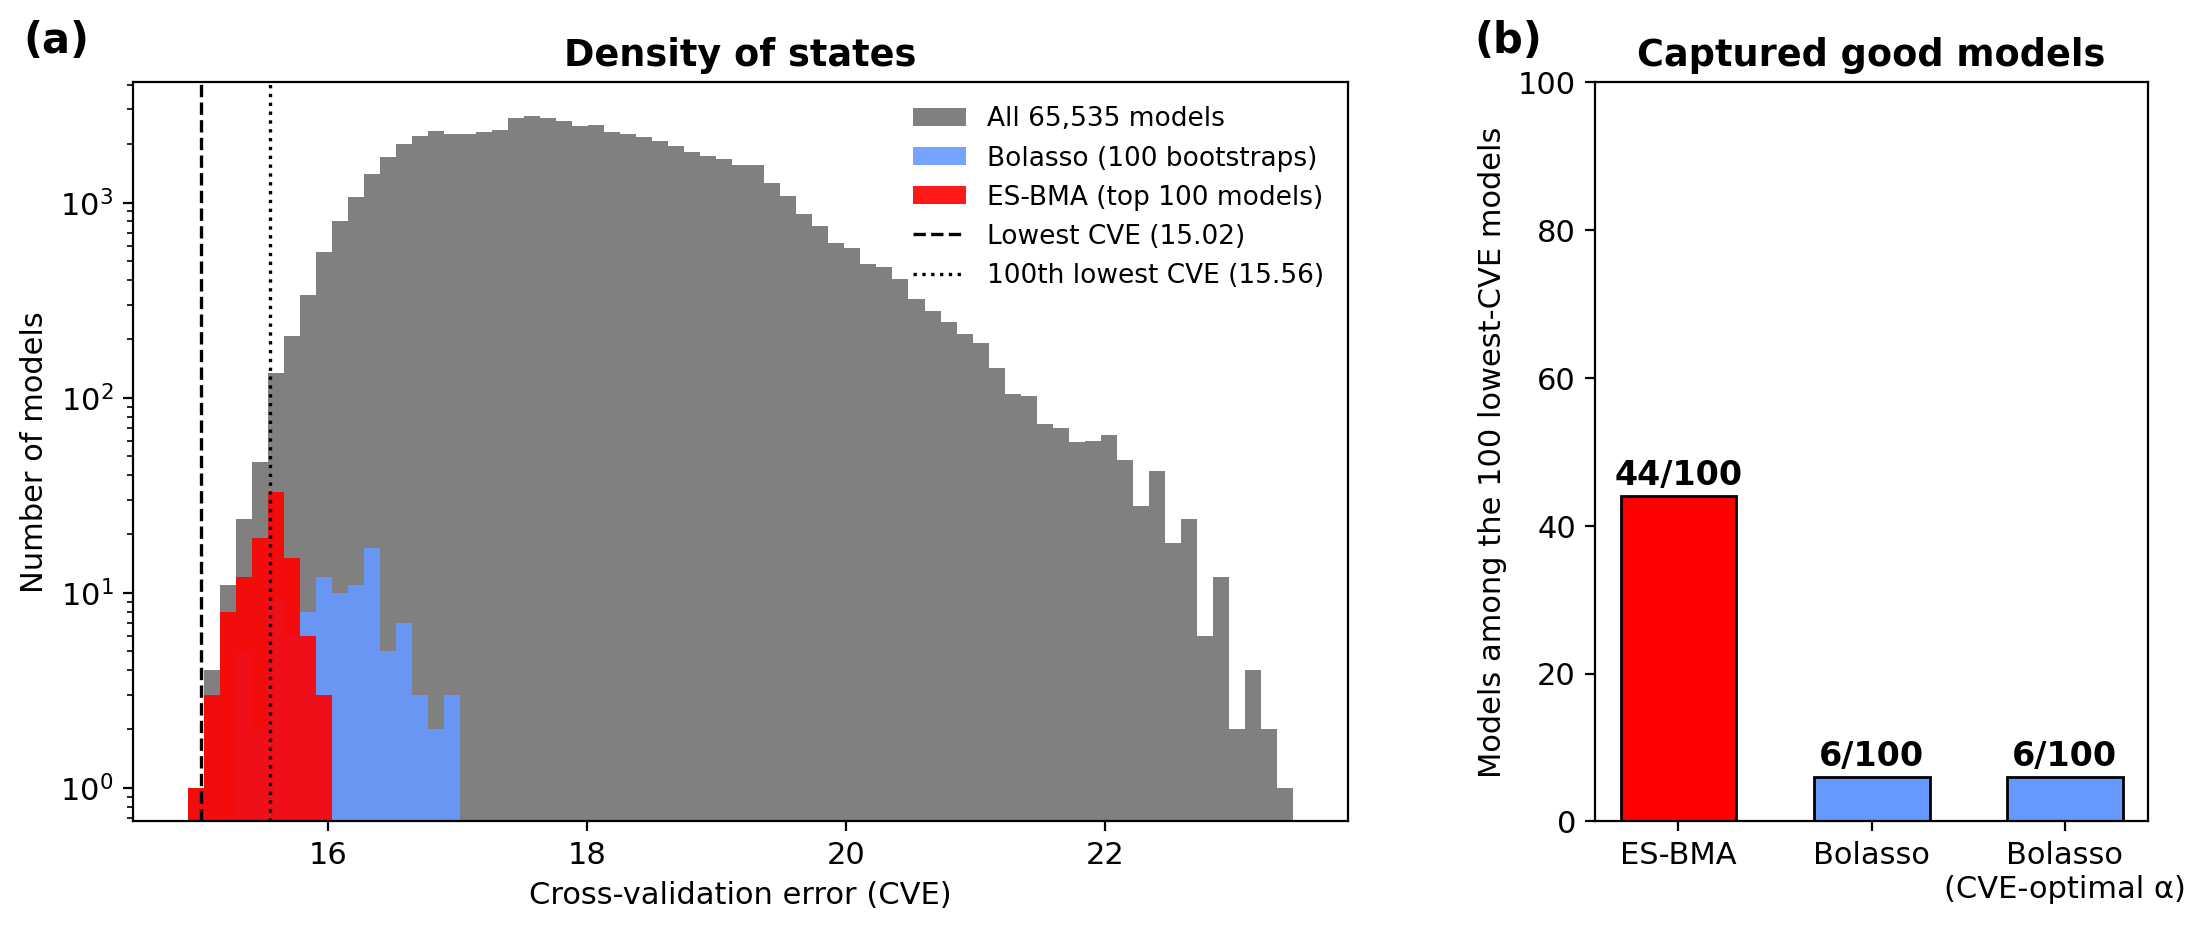

In [7]:
RECOMPUTE_FIG7 = RECOMPUTE_ALL
st = pd.read_csv(f"{INTER}/fig7_dos_cve_real_states.csv.gz"); st["mask"] = st["mask"].astype(np.int64)
bol = pd.read_csv(f"{INTER}/fig7_bolasso_supports_real_fixed.csv"); bopt = pd.read_csv(f"{INTER}/fig7_bolasso_supports_cveopt_real_fixed.csv")
ll7 = np.load(f"{INTER}/esbma_yield_g30.npz")["loglik"]; ind7 = ((np.arange(len(ll7))[:, None] >> np.arange(16)) & 1)
if RECOMPUTE_FIG7:
    t = time.time(); st_new = dos.all_states(X, y, D.YIELD_COLS, n_jobs=N_JOBS)
    cmp = st.set_index("mask")["cve"].reindex(st_new["mask"]).to_numpy()
    print("DoS recomputed in %.0f s; max |Δ CVE| = %.2e" % (time.time() - t, np.abs(st_new["cve"].to_numpy() - cmp).max()))
    st_new.to_csv(f"{RES}/fig7_dos_cve_real_states.csv.gz", index=False); st = st_new
    r = fit_g30(); print("max |Δ loglik| (unified fit) = %.2e" % np.abs(r["log_likelihoods"] - ll7).max())
    ind7, ll7 = r["indicators"], r["log_likelihoods"]
    if os.path.exists(f"{RES}/fig7_bolasso_supports_real_fixed.csv"):   # written by the Fig 4 recomputation
        nb_ = pd.read_csv(f"{RES}/fig7_bolasso_supports_real_fixed.csv")
    else:
        nb_ = pd.DataFrame(bolasso.bolasso_rate(X, y, D.YIELD_COLS, guard="zero")[1])
    t = time.time(); _, rows, a = bolasso.bolasso_cveopt(X, y, D.YIELD_COLS, guard="zero")
    no_ = pd.DataFrame(rows); no_.to_csv(f"{RES}/fig7_bolasso_supports_cveopt_real_fixed.csv", index=False)
    print("CVE-optimal Bolasso recomputed in %.0f s (alpha = %.4g)" % (time.time() - t, a))
    print("identical bootstrap supports: Bolasso", (nb_["mask"].to_numpy() == bol["mask"].to_numpy()).all(),
          "| CVE-opt Bolasso", (no_["mask"].to_numpy() == bopt["mask"].to_numpy()).all())
    bol, bopt = nb_, no_

cve = dict(zip(st["mask"], st["cve"])); rank = dict(zip(st["mask"], st["rank"])); top100 = set(st["mask"].iloc[:100])
masks7 = esbma.indicator_to_mask(ind7); es100 = masks7[np.argsort(-ll7)[:100]]
ub, uo = bol["mask"].unique(), bopt["mask"].unique()
ranks_b = [rank[m] for m in bol["mask"]]
check("Fig 7", "lowest CVE", round(float(st.cve.iloc[0]), 2), 15.02, 0.005)
check("Fig 7", "features of lowest-CVE model", mask_to_names(st["mask"].iloc[0]), ["x2", "x8", "x10", "x11", "x13", "x14", "x16"])
check("Fig 7", "Bolasso distinct models", len(ub), 79)
check("Fig 7", "Bolasso mean model size", round(float(bol["size"].mean()), 1), 10.9, 0.05)
check("Fig 7", "Bolasso best CVE rank", int(min(ranks_b)), 19)
check("Fig 7", "Bolasso median CVE rank", int(np.median(ranks_b)), 1906)
check("Fig 7", "Bolasso models in CVE top 100", int(sum(m in top100 for m in ub)), 6)
check("Fig 7", "CVE-opt Bolasso distinct models", len(uo), 67)
check("Fig 7", "CVE-opt Bolasso models in CVE top 100", int(sum(m in top100 for m in uo)), 6)
check("Fig 7", "ES-BMA top-100 models in CVE top 100", len(set(es100) & top100), 44)
bfe_rank = dict(zip(masks7[np.argsort(-ll7)], np.arange(1, len(ll7) + 1)))
five = sum(1 << D.PAPER_NAMES.index(v) for v in ["x2", "x8", "x13", "x14", "x16"])
check("Fig 7", "CVE rank of the lowest-BFE model", int(rank[int(es100[0])]), 18)
check("Fig 7", "BFE rank of the lowest-CVE model", int(bfe_rank[int(st["mask"].iloc[0])]), 3)
check("Fig 7", "CVE rank of {x2,x8,x13,x14,x16}", int(rank[five]), 64)
check("Fig 7", "BFE rank of {x2,x8,x13,x14,x16}", int(bfe_rank[five]), 38)
print("CVE of the 100th model: %.2f" % st.cve.iloc[99])

cap = [len(set(es100) & top100), sum(m in top100 for m in ub), sum(m in top100 for m in uo)]
fig = plt.figure(figsize=(13, 4.8)); gs = fig.add_gridspec(1, 2, width_ratios=[2.2, 1], wspace=0.28)
a = fig.add_subplot(gs[0]); b = fig.add_subplot(gs[1])
bins = np.linspace(st.cve.min() - 0.1, min(st.cve.max(), 24), 70)
a.hist(st.cve, bins=bins, color=GRAY, label="All 65,535 models")
a.hist([cve[m] for m in bol["mask"]], bins=bins, color=BLUE, alpha=0.9, label="Bolasso (100 bootstraps)")
a.hist([cve[int(m)] for m in es100], bins=bins, color=RED, alpha=0.9, label="ES-BMA (top 100 models)")
a.axvline(st.cve.iloc[0], color="black", ls="--", lw=1.2, label=f"Lowest CVE ({st.cve.iloc[0]:.2f})")
a.axvline(st.cve.iloc[99], color="black", ls=":", lw=1.2, label=f"100th lowest CVE ({st.cve.iloc[99]:.2f})")
a.set_yscale("log"); a.set_xlabel("Cross-validation error (CVE)"); a.set_ylabel("Number of models")
a.legend(fontsize=9.5, frameon=False, loc="upper right"); a.set_title("Density of states", fontweight="bold")
a.text(-0.09, 1.04, "(a)", transform=a.transAxes, fontsize=15, fontweight="bold")
b.bar(range(3), cap, color=[RED, BLUE, BLUE], edgecolor="black", width=0.6)
for i_, v in enumerate(cap): b.text(i_, v + 1.5, f"{v}/100", ha="center", fontsize=12, fontweight="bold")
b.set_xticks(range(3)); b.set_xticklabels(["ES-BMA", "Bolasso", "Bolasso\n(CVE-optimal α)"]); b.set_ylim(0, 100)
b.set_ylabel("Models among the 100 lowest-CVE models"); b.set_title("Captured good models", fontweight="bold")
b.text(-0.22, 1.04, "(b)", transform=b.transAxes, fontsize=15, fontweight="bold")
fig.savefig(f"{FIGS}/Fig7_dos.png", dpi=200, bbox_inches="tight"); plt.close(fig)
show(f"{FIGS}/Fig7_dos.png")

## 6. Fig 8 – feature posterior vs sample size (yield)

Subsampling ("bootstrap ES-BMA", `notebook/experiment3/esbma_nanosheet.py`, launched by `esbma_nanosheet.sh`, logs
`20231031_<n>.log`, results `output/exp31/<n>/trial_<i>/`): for n = 30, 35, …, 80 and trials i = 0…29,
`random.seed(i)`, n samples drawn **with replacement** from the 80 (`random.choices`). Same sampling and seeds as
the original runs, ES-BMA with the unified grid, computed by `scripts/recompute_grid30/` (one JSON per trial, collected
into `fig8_fig9_subsampling_trials.csv` by `aggregate.py`; rows `target == "yield_exp31"`). The original 20-point-grid
trials are kept in `data/intermediate/legacy/`. Panels (a)–(c): mean posterior of each
descriptor over the 30 trials for n = 30, 45, 60; (d), (e): box plots (Tukey, 1.5 IQR) of the posteriors of x9 and x13
vs n. The drawing code is `make_fig8.py` (used to redraw the published figure), copied unchanged to
`src/esbma_repro/make_fig8.py`. The median and inter-quartile range of the x9 and x13 posteriors at
n = 30 and 80 are printed for comparison with the text.

Expected (unified grid): x13 median posterior 0.63 at n = 30 → 0.97 at n = 80; x9 stays at 0.45.
*Recompute here*: fast evaluator, ≈ 10 s per trial on one core (all 330 trials ≈ 1 CPU-h); `ESBMA_QUICK=1` → trial 0 at
n = 30 and 80. The full set of 1,290 trials is best run with `scripts/recompute_grid30/launch.sh run_all` (11 min with 100
worker processes).

n=30 trial=0: same sample indices; max |Δ posterior| = 1.11e-16


n=80 trial=0: same sample indices; max |Δ posterior| = 1.11e-16
recomputed 2 trial(s) in 20 s
mean posterior over 30 trials (rows: n):
         x1    x2    x3    x4    x5    x6    x7    x8    x9   x10   x11   x12   x13   x14   x15   x16
n_dir                                                                                                
30     0.40  0.60  0.44  0.56  0.52  0.44  0.48  0.67  0.45  0.41  0.53  0.51  0.64  0.66  0.40  0.52
35     0.40  0.62  0.40  0.56  0.52  0.41  0.46  0.71  0.46  0.37  0.56  0.48  0.70  0.68  0.37  0.51
40     0.38  0.66  0.39  0.55  0.54  0.40  0.45  0.73  0.46  0.38  0.58  0.47  0.76  0.73  0.36  0.53
45     0.37  0.70  0.38  0.58  0.51  0.39  0.45  0.73  0.46  0.37  0.60  0.47  0.78  0.77  0.36  0.55
50     0.34  0.76  0.39  0.54  0.52  0.37  0.43  0.74  0.48  0.38  0.62  0.46  0.82  0.82  0.36  0.60
55     0.34  0.80  0.38  0.53  0.51  0.36  0.42  0.73  0.48  0.38  0.64  0.44  0.84  0.86  0.37  0.59
60     0.34  0.82  0.37  0.50  0.53  0.36  0.41  

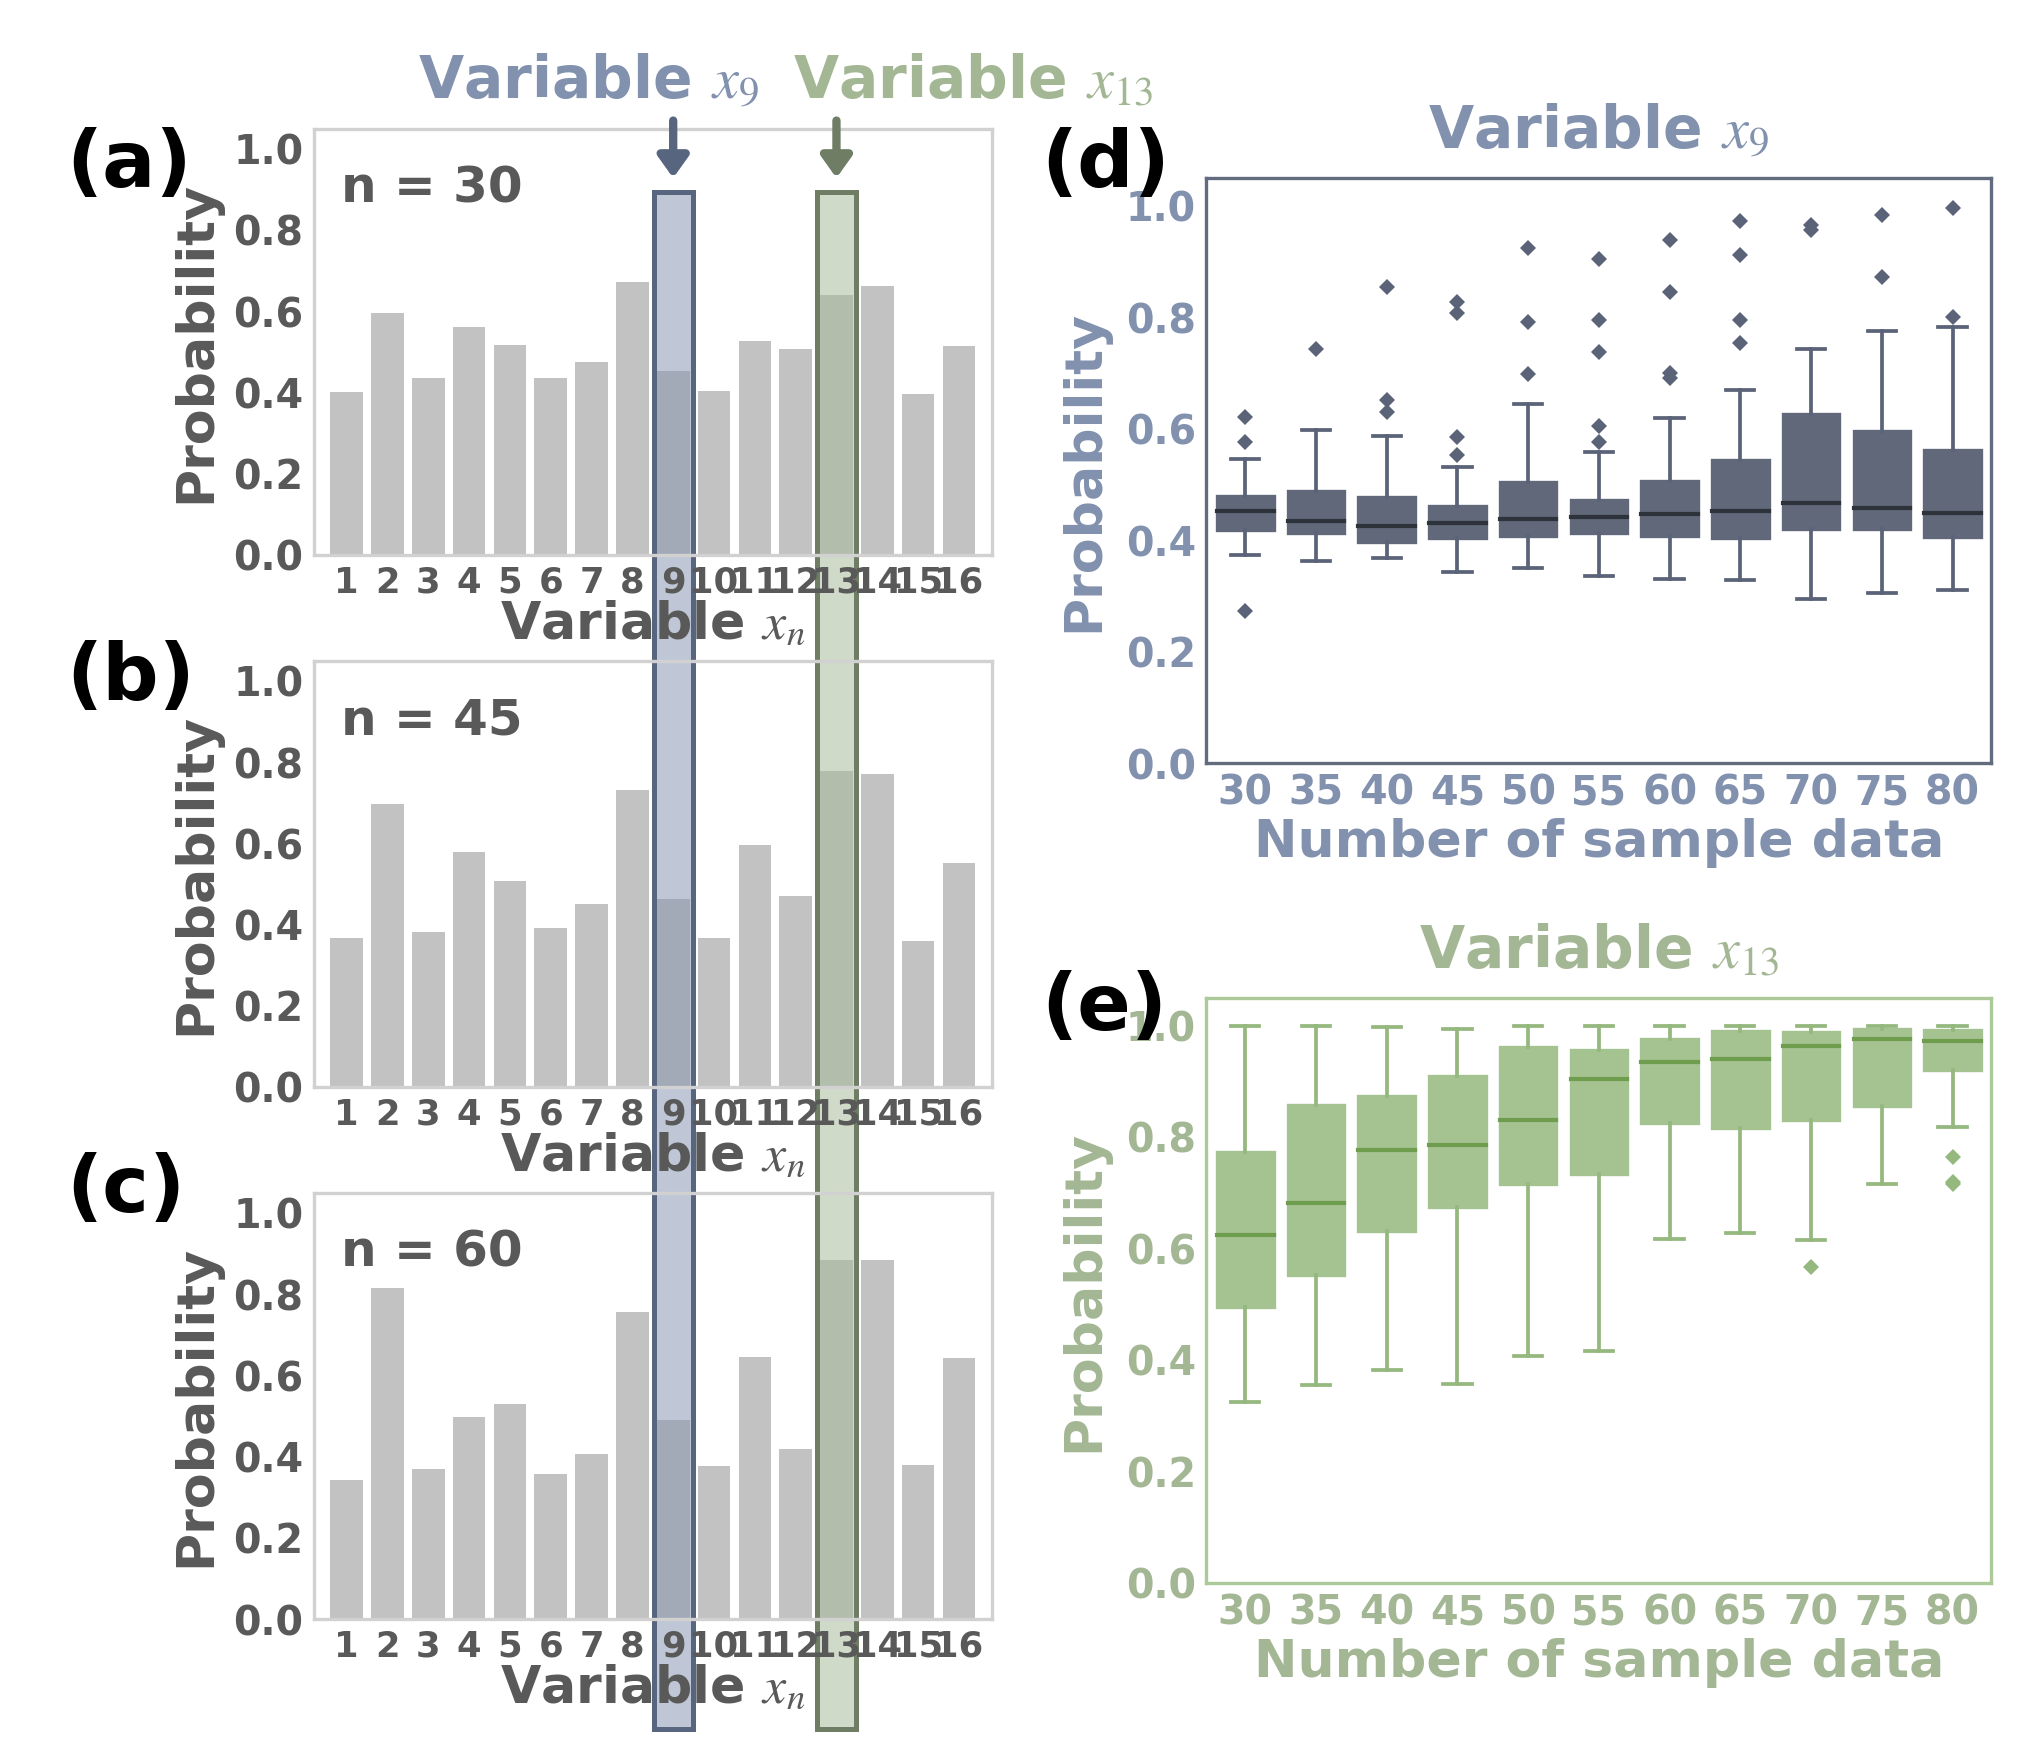

In [8]:
RECOMPUTE_FIG8 = RECOMPUTE_ALL
TR = pd.read_csv(f"{INTER}/fig8_fig9_subsampling_trials.csv")
Y8 = TR[TR.target == "yield_exp31"].copy()
assert (Y8.n_dir == Y8.n_actual).all()
if RECOMPUTE_FIG8:
    Xy, yy, _ = D.load("yield", RAW)
    todo = [(30, 0), (80, 0)] if QUICK else [(n, t_) for n in range(30, 85, 5) for t_ in range(30)]
    t = time.time(); new = []
    for n, t_ in todo:
        idx, fpost = subsample.run_trial(Xy, yy, n, t_, use_exhbma=USE_EXHBMA, n_jobs=N_JOBS)
        old = Y8[(Y8.n_dir == n) & (Y8.trial == t_)].iloc[0]
        assert idx == list(map(int, old.sample_indexs.split())), "sample indices differ"
        print(f"n={n} trial={t_}: same sample indices; max |Δ posterior| = {np.abs(fpost - old[D.YIELD_COLS].to_numpy(float)).max():.2e}")
        new.append(dict(n_dir=n, trial=t_, **dict(zip(D.YIELD_COLS, fpost))))
    print("recomputed %d trial(s) in %.0f s" % (len(todo), time.time() - t))
    pd.DataFrame(new).to_csv(f"{RES}/fig8_trials.csv", index=False)
    if not QUICK:
        Y8 = Y8.drop(columns=D.YIELD_COLS).merge(pd.DataFrame(new), on=["n_dir", "trial"])

ns = sorted(Y8.n_dir.unique())
mean8 = Y8.groupby("n_dir")[D.YIELD_COLS].mean(); mean8.columns = D.PAPER_NAMES
print("mean posterior over 30 trials (rows: n):"); print(mean8.round(2).to_string())
for v in ("x9", "x13"):
    col = D.YIELD_COLS[D.PAPER_NAMES.index(v)]
    med = Y8.groupby("n_dir")[col].median()
    print(f"{v}: median posterior n=30 {med.loc[30]:.2f} -> n=80 {med.loc[80]:.2f}; IQR n=30 "
          f"{Y8[Y8.n_dir == 30][col].quantile(.75) - Y8[Y8.n_dir == 30][col].quantile(.25):.2f} -> n=80 "
          f"{Y8[Y8.n_dir == 80][col].quantile(.75) - Y8[Y8.n_dir == 80][col].quantile(.25):.2f}")
    check("Fig 8", f"{v}: median posterior n = 30 -> n = 80", (round(med.loc[30], 2), round(med.loc[80], 2)),
          {"x9": (0.45, 0.45), "x13": (0.63, 0.97)}[v])
# paper layout: (a)-(c) mean posteriors for n = 30, 45, 60; (d), (e) box plots of x9 and x13 (src/esbma_repro/make_fig8.py)
data8 = {n: Y8[Y8.n_dir == n].sort_values("trial")[D.YIELD_COLS].to_numpy() for n in ns}
with plt.rc_context():
    from esbma_repro import make_fig8
    fig = make_fig8.make_figure(data8)
    fig.savefig(f"{FIGS}/Fig8_sample_size.png", dpi=300, facecolor="white"); plt.close(fig)
show(f"{FIGS}/Fig8_sample_size.png")

## 7. Fig 9 – mean posterior of the maximum / minimum feature vs number of samples

Same subsampling procedure for the three targets (`katsuta/notebook/experiment3/{yield,size,size_distribution}/`;
yield trials are identical to Section 6), recomputed with the unified grid by `scripts/recompute_grid30/`. For each n
the mean over trials 0–29 is plotted (as in `katsuta_analysis/analyze.py`) for the descriptors of the published figure:
yield – x34 (paper x14, Max) / x5 (paper x3, Min); size – x4 / x21; size distribution – x32 / x8 (column names of the
respective data tables). The means are recomputed from the per-trial table and compared with `fig9_mean_fp_pickles.csv`
written by `aggregate.py`.

Expected (unified grid): the Max curve first exceeds 0.75 at n = 45 (yield), 65 (size distribution) and 65 (size, x4).
With the unified grid the size descriptor with the highest posterior at n = 120 is x16 (0.830), essentially tied with x4
(0.819); x16 crosses 0.75 at n = 100.

Corrections relative to the original runs: the size run labelled n = 85 now uses 85 samples (the original had been
launched with 95), and every study has exactly 30 trials. *Recompute here*: fast evaluator (size: 2<sup>18</sup> models,
≈ 45 s per trial on one core); `ESBMA_QUICK=1` → trial 0 at n = 30 for size and size distribution.

size n=30 trial=0: same indices; max |Δ posterior| = 5.55e-17


size_distribution n=30 trial=0: same indices; max |Δ posterior| = 5.55e-17
recomputed 2 trial(s) in 46 s
yield              max |mean(trials 0-29) - pickle| = 1.1e-16; Max x34: 0.66 (n=30) -> 0.95 (n=80); Min x5: 0.44 -> 0.34
[OK ] Fig 9: yield: means reproduce fig9_mean_fp_pickles.csv = True  (expected: True)
[OK ] Fig 9: yield: n at which the Max curve first exceeds 0.75 = 45  (expected: 45)
size               max |mean(trials 0-29) - pickle| = 1.1e-16; Max x4: 0.62 (n=30) -> 0.82 (n=120); Min x21: 0.47 -> 0.37
[OK ] Fig 9: size: means reproduce fig9_mean_fp_pickles.csv = True  (expected: True)
[OK ] Fig 9: size: n at which the Max curve first exceeds 0.75 = 65  (expected: 65)
size_distribution  max |mean(trials 0-29) - pickle| = 2.2e-16; Max x32: 0.62 (n=30) -> 0.84 (n=90); Min x8: 0.42 -> 0.38
[OK ] Fig 9: size_distribution: means reproduce fig9_mean_fp_pickles.csv = True  (expected: True)
[OK ] Fig 9: size_distribution: n at which the Max curve first exceeds 0.75 = 65  (expected: 

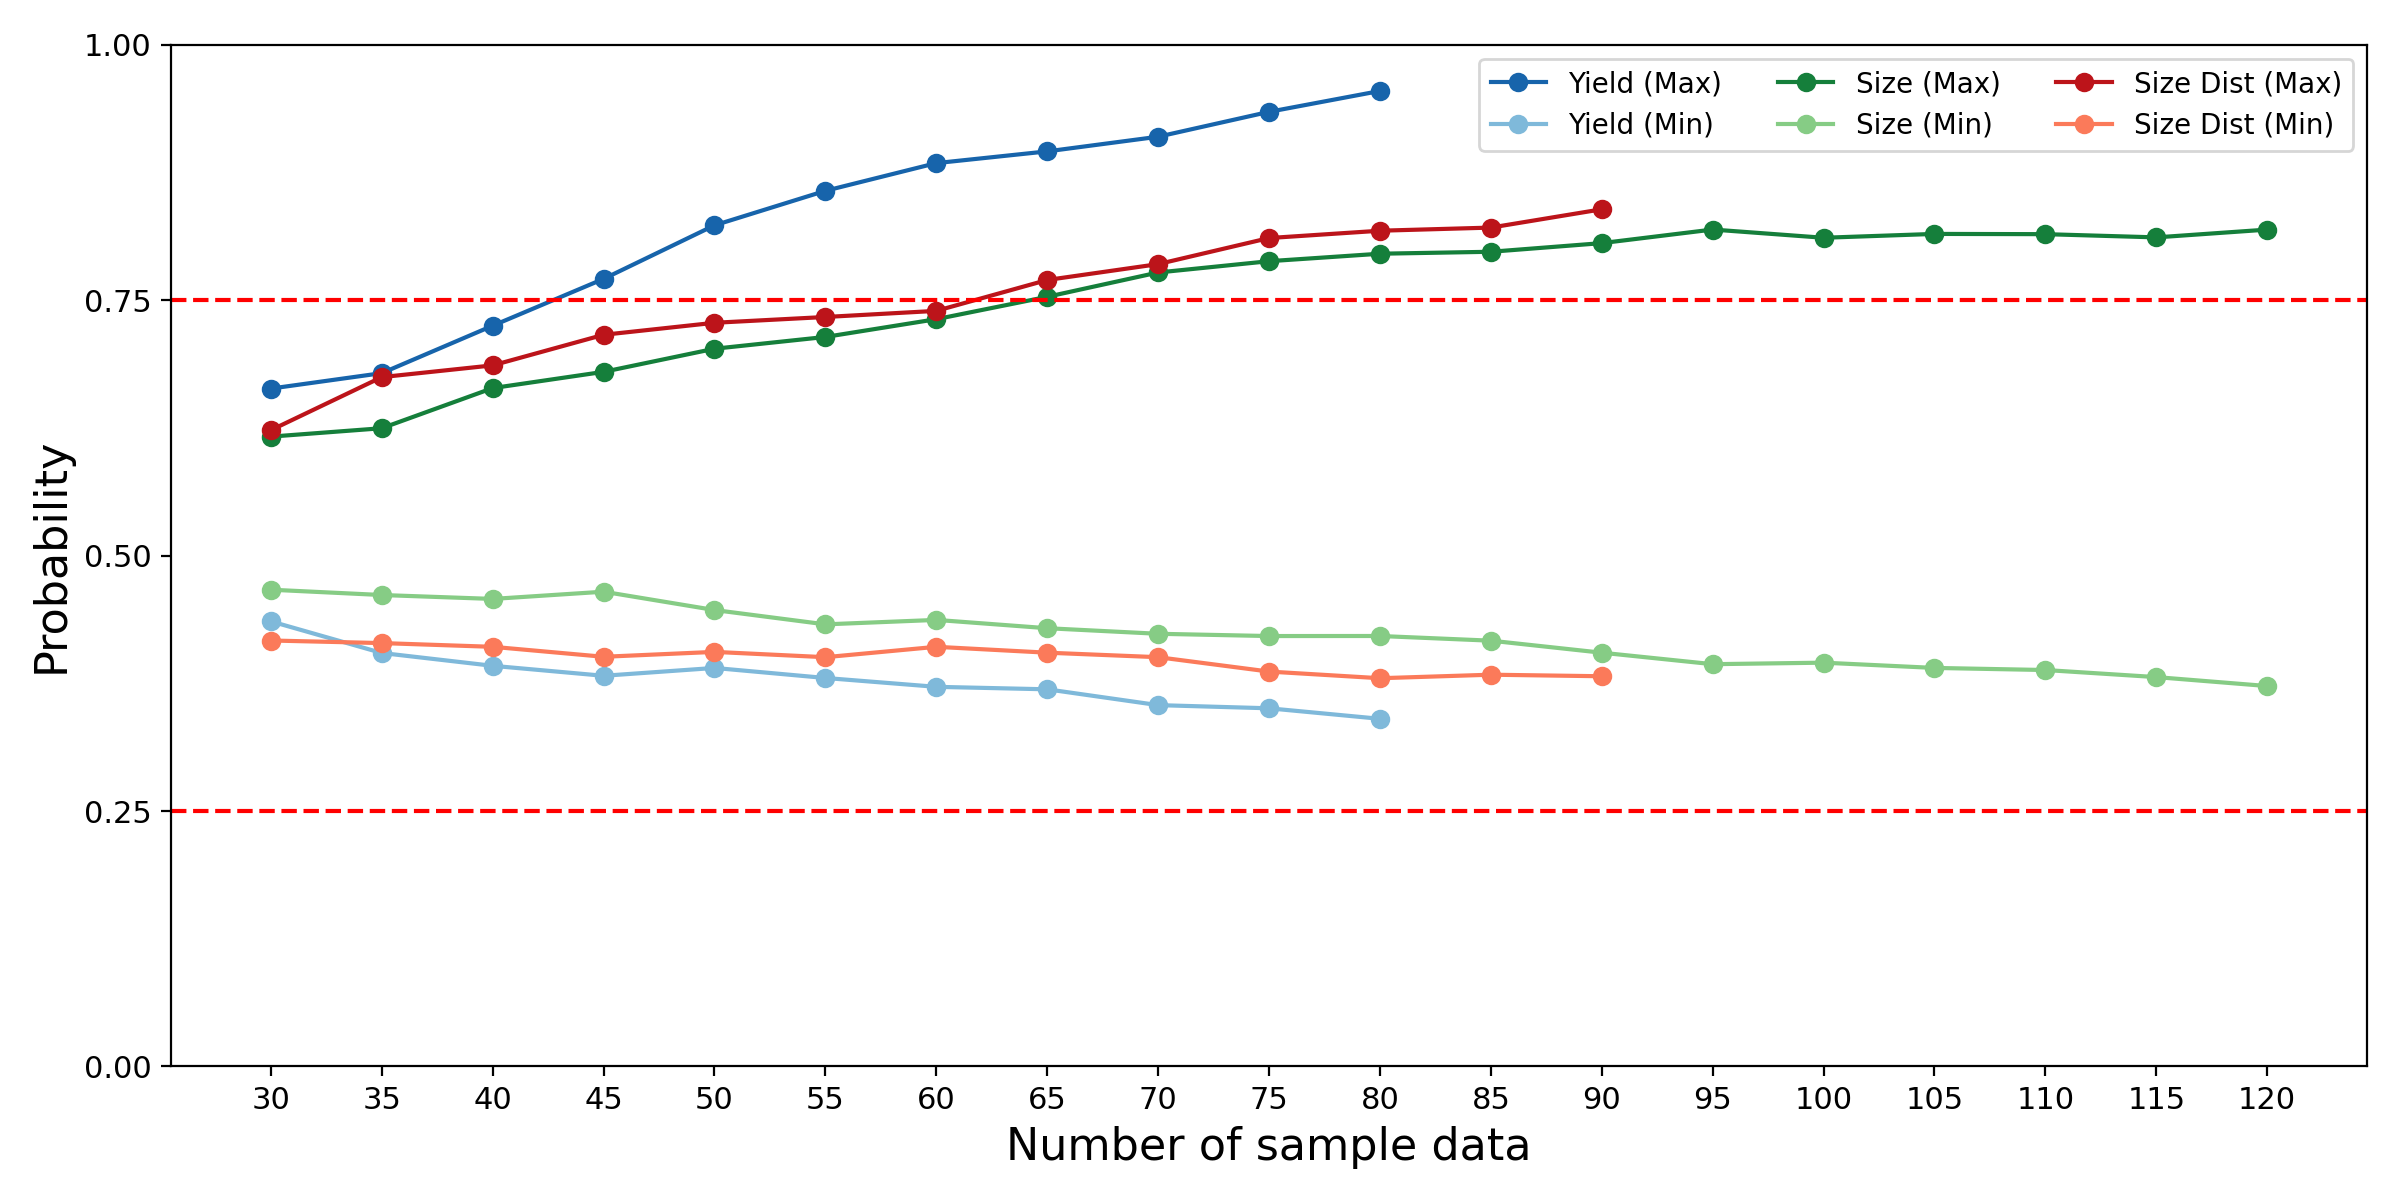

In [9]:
RECOMPUTE_FIG9 = RECOMPUTE_ALL
MP = pd.read_csv(f"{INTER}/fig9_mean_fp_pickles.csv")
SPEC = {"yield": ("yield_katsuta", "x34", "x5", "Blues"), "size": ("size", "x4", "x21", "Greens"),
        "size_distribution": ("size_distribution", "x32", "x8", "Reds")}
if RECOMPUTE_FIG9:
    todo = [("size", 30, 0), ("size_distribution", 30, 0)] if QUICK else \
           [(tg, n, t_) for tg, ns_ in [("yield", range(30, 85, 5)), ("size", range(30, 125, 5)), ("size_distribution", range(30, 95, 5))]
            for n in ns_ for t_ in range(30)]
    t = time.time()
    for tg, n, t_ in todo:
        Xt, yt, ct = D.load(tg, RAW)
        idx, fpost = subsample.run_trial(Xt, yt, n, t_, use_exhbma=USE_EXHBMA, n_jobs=N_JOBS)
        old = TR[(TR.target == SPEC[tg][0]) & (TR.n_dir == n) & (TR.trial == t_)].iloc[0]
        assert idx == list(map(int, old.sample_indexs.split()))
        print(f"{tg} n={n} trial={t_}: same indices; max |Δ posterior| = {np.abs(fpost - old[ct].to_numpy(float)).max():.2e}")
    print("recomputed %d trial(s) in %.0f s" % (len(todo), time.time() - t))

fig, ax = plt.subplots(figsize=(12, 6)); xs = np.arange(30, 125, 5)
for tg, (src, cmax, cmin, cmap) in SPEC.items():
    T = TR[(TR.target == src) & (TR.trial < 30)]
    mean = T.groupby("n_dir")[[cmax, cmin]].mean()
    ref = MP[MP.target == tg].set_index("n")[[cmax, cmin]]
    print(f"{tg:18s} max |mean(trials 0-29) - pickle| = {np.abs(mean.loc[ref.index] - ref).max().max():.1e}; "
          f"Max {cmax}: {mean[cmax].iloc[0]:.2f} (n={mean.index[0]}) -> {mean[cmax].iloc[-1]:.2f} (n={mean.index[-1]}); "
          f"Min {cmin}: {mean[cmin].iloc[0]:.2f} -> {mean[cmin].iloc[-1]:.2f}")
    check("Fig 9", f"{tg}: means reproduce fig9_mean_fp_pickles.csv", bool(np.abs(mean.loc[ref.index] - ref).max().max() < 1e-12), True)
    check("Fig 9", f"{tg}: n at which the Max curve first exceeds 0.75", int(next(n for n, v in mean[cmax].items() if v > 0.75)),
          {"yield": 45, "size": 65, "size_distribution": 65}[tg])
    c = plt.get_cmap(cmap)
    lab = {"yield": "Yield", "size": "Size", "size_distribution": "Size Dist"}[tg]
    ax.plot(mean.index.to_numpy(), mean[cmax].to_numpy(), "o-", color=c(0.8), label=f"{lab} (Max)")
    ax.plot(mean.index.to_numpy(), mean[cmin].to_numpy(), "o-", color=c(0.45), label=f"{lab} (Min)")
ax.axhline(0.75, color="red", ls="--"); ax.axhline(0.25, color="red", ls="--")
ax.set_ylim(0, 1); ax.set_yticks([0, .25, .5, .75, 1]); ax.set_xticks(xs)
ax.set_xlabel("Number of sample data", fontsize=16); ax.set_ylabel("Probability", fontsize=16); ax.legend(ncol=3, fontsize=10)
fig.tight_layout(); fig.savefig(f"{FIGS}/Fig9_mean_posterior_vs_n.png", dpi=200); plt.close(fig)
show(f"{FIGS}/Fig9_mean_posterior_vs_n.png")

## 8. Summary of reproduced numbers

In [10]:
summary = pd.DataFrame(CHECKS)
summary.to_csv(f"{FIGS}/checks_summary.csv", index=False)
print(summary.to_string(index=False))
print("\n%d of %d checks match the expected values." % (summary["match"].sum(), len(summary)))

      item                                                         quantity                                        reproduced                                          expected  match
     Fig 3 variables in >= 50 of the top-100 models, all with the same sign                  [x2, x8, x9, x11, x13, x14, x16]                  [x2, x8, x9, x11, x13, x14, x16]   True
     Fig 3               variables in all 100 top models with the same sign                               [x8, x13, x14, x16]                               [x8, x13, x14, x16]   True
     Fig 3                      x2: number of top-100 models (all positive)                                                99                                                99   True
     Fig 3                          CVE median / min / max, BFE ranks 1-100                             (15.57, 15.02, 15.98)                             (15.57, 15.02, 15.98)   True
     Fig 3                  CVE median / min / max, BFE ranks 59,951-60,050          